In [ ]:
import sys; sys.path.insert(0, '../../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import warnings
warnings.filterwarnings('ignore')

import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
sns.set()
# sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from load_everything import *
from harness import *
import pickle

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )

from f2_utils import *
import time_in_each_roi
import matplotlib.patches as patches
import time_in_each_roi
from sklearn.linear_model import MultiTaskLassoCV,LassoCV
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.model_selection import train_test_split


# make sure linear model and CNN use the same training data

In [3]:
prefix = '/mnt/staging/'
fetch_path = str(PREPARES / "modeling") + "/"
mouse = 'cm219'
data_joint = load_model(fetch_path+mouse+'_data_joint.pickle')

In [4]:
# Define the threshold
threshold = 0.01

# Create a filtered dataframe by keeping only rows where is_groom is <= 0.1
data_joint_filtered = data_joint[data_joint['is_groom'] <= threshold].copy()
# data_joint_filtered = data_joint_filtered[data_joint_filtered['LFP_vel'] <= 0.3].copy()

# Calculate statistics for your report
original_rows = len(data_joint)
filtered_rows = len(data_joint_filtered)
removed_rows = original_rows - filtered_rows

print(f"Original shape: {data_joint.shape}")
print(f"Filtered shape: {data_joint_filtered.shape}")
print(f"Removed {removed_rows} time frames (rows) where is_groom > {threshold}")


# # --- NEW: Remove tail flipping artifacts ---
# # Condition: Remove rows where ANY value in the first 1000 columns has abs > 0.15
# artifact_threshold = 0.15

# # 1. Identify rows to drop (True if any column in 0-1000 > 0.15)
# # We use .iloc[:, :1000] to select the first 1000 columns by position
# has_artifact = (data_joint_filtered.iloc[:, 315+500:316+500].abs() > artifact_threshold).any(axis=1)

# # 2. Filter the dataframe (Keep rows that do NOT have artifacts)
# data_joint_clean = data_joint_filtered[~has_artifact].copy()

# # --- Print updated statistics ---
# rows_before_artifact_removal = len(data_joint_filtered)
# rows_after_artifact_removal = len(data_joint_clean)
# removed_artifact_rows = rows_before_artifact_removal - rows_after_artifact_removal

# print(f"Shape before artifact removal: {data_joint_filtered.shape}")
# print(f"Shape after artifact removal:  {data_joint_clean.shape}")
# print(f"Removed {removed_artifact_rows} rows due to tail flipping (abs > {artifact_threshold} in first 1000 cols)")

# # Update your main variable if desired
# data_joint_filtered = data_joint_clean

Original shape: (55230, 1008)
Filtered shape: (55077, 1008)
Removed 153 time frames (rows) where is_groom > 0.01


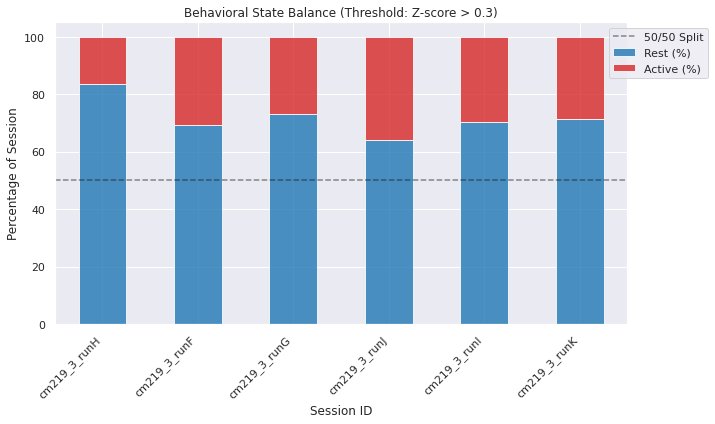

              Active (%)   Rest (%)  Total Frames
Session                                          
cm219_3_runH   16.491037  83.508963          9205
cm219_3_runF   30.662558  69.337442          9086
cm219_3_runG   27.050516  72.949484          9205
cm219_3_runJ   36.104461  63.895539          9190
cm219_3_runI   29.577618  70.422382          9186
cm219_3_runK   28.506247  71.493753          9205


In [5]:


# 1. Define Threshold for Locomotion
# Since data is z-scored:
# > 0.5 or 1.0 is typically "active" movement
# < 0.5 is typically "rest" or microutterances
VEL_THRESHOLD = 0.3

# 2. Calculate Balance per Session
session_balance = []
unique_sessions = data_joint_filtered.index.get_level_values(0).unique()

for session in unique_sessions:
    # Get velocity data for this session
    session_vel = data_joint_filtered.loc[session]['log_FPs_pc']
    
    # Count frames
    total_frames = len(session_vel)
    active_frames = (session_vel > VEL_THRESHOLD).sum()
    rest_frames = total_frames - active_frames
    
    # Calculate percentages
    pct_active = (active_frames / total_frames) * 100
    pct_rest = (rest_frames / total_frames) * 100
    
    session_balance.append({
        'Session': session,
        'Active (%)': pct_active,
        'Rest (%)': pct_rest,
        'Total Frames': total_frames
    })

# Create DataFrame
balance_df = pd.DataFrame(session_balance).set_index('Session')

# 3. Visualization
fig, ax = plt.subplots(figsize=(10, 6))

# Plot Stacked Bar Chart
balance_df[['Rest (%)', 'Active (%)']].plot(
    kind='bar', 
    stacked=True, 
    color=['#1f77b4', '#d62728'], # Blue for Rest, Red for Active
    ax=ax,
    alpha=0.8
)

# Add threshold line for 50% balance
ax.axhline(50, color='k', linestyle='--', alpha=0.5, label='50/50 Split')

plt.title(f'Behavioral State Balance (Threshold: Z-score > {VEL_THRESHOLD})')
plt.ylabel('Percentage of Session')
plt.xlabel('Session ID')
plt.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

plt.show()

# Print numeric table to check exact values
print(balance_df)

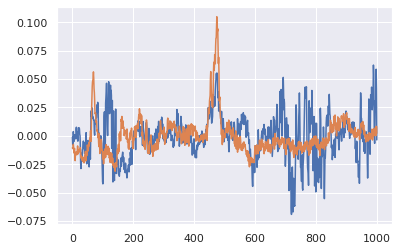

In [355]:
# plt.plot(np.array(data_joint_filtered.iloc[:1000, 315]))
# plt.plot(np.array(data_joint_filtered.iloc[:1000, 315+500]))

plt.plot(np.array(data_joint_filtered.iloc[:1000, 390]))
plt.plot(np.array(data_joint_filtered.iloc[:1000, 390+500]))

In [356]:
data_joint_filtered.shape

(55011, 1008)

In [357]:
data_joint.head()

0         1         2         3         4         5  \
row_level                                                                    
cm219_3_runH 0 -0.000445  0.001678 -0.000097 -0.000692  0.007831 -0.002456   
             1 -0.000810  0.002985 -0.000925 -0.000336 -0.019354 -0.003150   
             2  0.002432  0.004734  0.001956  0.003368 -0.009257  0.000588   
             3  0.003453  0.004307  0.002570  0.004064  0.015164  0.001397   
             4  0.004740  0.005706  0.004129  0.005163  0.017337  0.001049   

                       6         7         8         9  ...       498  \
row_level                                               ...             
cm219_3_runH 0 -0.000255 -0.001184 -0.001779  0.000255  ... -0.048484   
             1  0.004068 -0.002172 -0.003496  0.000626  ...  0.005768   
             2  0.007929  0.002051  0.000416  0.004124  ...  0.088199   
             3  0.006082  0.004574  0.001880  0.005644  ...  0.033078   
             4  0.006184  0.005210  0.002809  0.005241  ... -0.017481   

                     499   face_pc   body_pc      rotf  is_groom   RFP_vel  \
row_level                                                                    
cm219_3_runH 0  0.165771  3.271024 -0.186837 -0.040709       0.0 -0.038830   
             1  0.033287  2.987772 -0.168995 -0.125955       0.0 -0.050529   
             2  0.036841  2.878312 -0.177587 -0.039767       0.0 -0.052829   
             3  0.074521  2.850346 -0.172474 -0.072400       0.0 -0.075704   
             4  0.067189  2.861113 -0.197780 -0.226936       0.0 -0.107251   

                 LFP_vel  log_FPs_pc  log_RFP_vel  
row_level                                          
cm219_3_runH 0  0.005330    0.045034     0.337641  
             1 -0.027746    0.083568     0.311947  
             2 -0.050325    0.065116     0.306858  
             3 -0.078733    0.076119     0.255489  
             4 -0.113923    0.020978     0.182360  

[5 rows x 1008 columns]

In [358]:
def set_level_values(midx, level, values):
    full_levels = list(zip(*midx.values))
    names = midx.names
    if isinstance(level, str):
        if level not in names:
            raise ValueError(f'No level {level} in MultiIndex')
        level = names.index(level)
    if len(full_levels[level]) != len(values):
        raise ValueError('Values must be of the same size as original level')
    full_levels[level] = values
    return pd.MultiIndex.from_arrays(full_levels, names=names)

# Load cat data (same training data as 1D-CNN)

In [359]:
# hf = h5py.File(f4_locker_root+mouse+'_data_joint.pickle', 'r')
# H_cat=np.array(hf['H_cat'])
# all_bev_df_cat=pd.DataFrame(hf['all_bev_df_cat'],columns=['whisk_vel','rotf','is_groom','LFP'])

In [360]:
all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))
print(len(all_sessions),all_sessions)

6 ['cm219_3_runF', 'cm219_3_runG', 'cm219_3_runH', 'cm219_3_runI', 'cm219_3_runJ', 'cm219_3_runK']


In [361]:
# # Filter the dataframe to only keep rows where the session name (index level 0) contains 'cm219_4'
# data_joint_filtered = data_joint_filtered[data_joint_filtered.index.get_level_values(0).str.contains('cm219_3')]

# # Verify the result
# all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))
# print(f"Remaining sessions ({len(all_sessions)}): {all_sessions}")

In [362]:
# Define behavior columns to predict
behavior_cols = ['log_FPs_pc', 'RFP_vel','body_pc','RFP_vel','face_pc','log_RFP_vel']

# Extract neural activity and behaviors
Thy1_data = data_joint_filtered.iloc[:, :500]      # First 500 columns
CSNs_data = data_joint_filtered.iloc[:, 500:1000]  # Next 500 columns
behavior_data = data_joint_filtered[behavior_cols]  # 5 behavior columns
all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))



In [363]:
prefix = '/mnt/staging/' # or

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
sensory_ind = load_model(fetch_path_sensory+'brightest_ind_'+mouse)
if mouse == 'cm229':
    fetch_path_sensory = str(PREPARES / "index-M1") + "/"
    M1_ind = load_model(fetch_path_sensory+'M1_ind_'+mouse)
elif mouse == 'cm219':
    M1_ind = {'RFP':315}

In [364]:
print('S1 index:',412,'M1 index:',M1_ind['RFP'])

S1 index: 412 M1 index: 315


In [378]:
import pandas as pd
import numpy as np

# 1. Define Indices
# Thy1 Indices (from columns 0-499)
thy1_s1_idx = 404
thy1_m1_idx = M1_ind['RFP']

# CSN Indices (from columns 500-1000)
# ASSUMPTION: CSNs share the same ROI map, so we just add 500 to the index.
# If they have different indices, replace these numbers manually.
csn_s1_idx = 404 + 500
csn_m1_idx = M1_ind['RFP'] + 500

# 2. Setup Loop
behavior_cols = ['face_pc', 'body_pc', 'RFP_vel','log_FPs_pc','log_RFP_vel']
all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))
correlation_results = []

for session in all_sessions:
    # Get session data
    session_data = data_joint_filtered.loc[session]
    
    # Extract the 4 specific signals
    signals = {
        ('Thy1', 'S1'): session_data.iloc[:, thy1_s1_idx],
        ('Thy1', 'M1'): session_data.iloc[:, thy1_m1_idx],
        ('CSNs', 'S1'): session_data.iloc[:, csn_s1_idx],
        ('CSNs', 'M1'): session_data.iloc[:, csn_m1_idx]
    }
    
    # Calculate correlation for each behavior
    for behavior in behavior_cols:
        beh_signal = session_data[behavior]
        
        for (cell_type, region), neural_signal in signals.items():
            # Calculate Pearson Correlation (Linearity)
            r_val = neural_signal.corr(beh_signal)
            
            correlation_results.append({
                'Session': session,
                'Behavior': behavior,
                'Cell_Type': cell_type, # Thy1 or CSNs
                'Region': region,       # S1 or M1
                'Correlation': r_val
            })

# 3. Create Final DataFrame
linearity_df = pd.DataFrame(correlation_results)

# Preview
print(linearity_df.head())

        Session Behavior Cell_Type Region  Correlation
0  cm219_3_runF  face_pc      Thy1     S1     0.301816
1  cm219_3_runF  face_pc      Thy1     M1     0.494198
2  cm219_3_runF  face_pc      CSNs     S1     0.336494
3  cm219_3_runF  face_pc      CSNs     M1     0.416863
4  cm219_3_runF  body_pc      Thy1     S1     0.243661


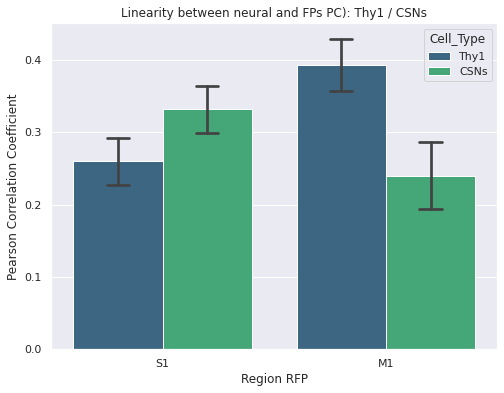

In [379]:
import seaborn as sns
import matplotlib.pyplot as plt



# Example: Plotting 'face_pc' behavior specifically
subset = linearity_df[linearity_df['Behavior'] == 'RFP_vel']

plt.figure(figsize=(8, 6))
sns.barplot(
    data=subset, 
    x='Region', 
    y='Correlation', 
    hue='Cell_Type', 
    palette='viridis',
    errorbar='se',  # Standard Error bars
    capsize=0.1
)

plt.title('Linearity between neural and FPs PC): Thy1 / CSNs')
plt.ylabel('Pearson Correlation Coefficient')
plt.xlabel('Region RFP')
plt.show()

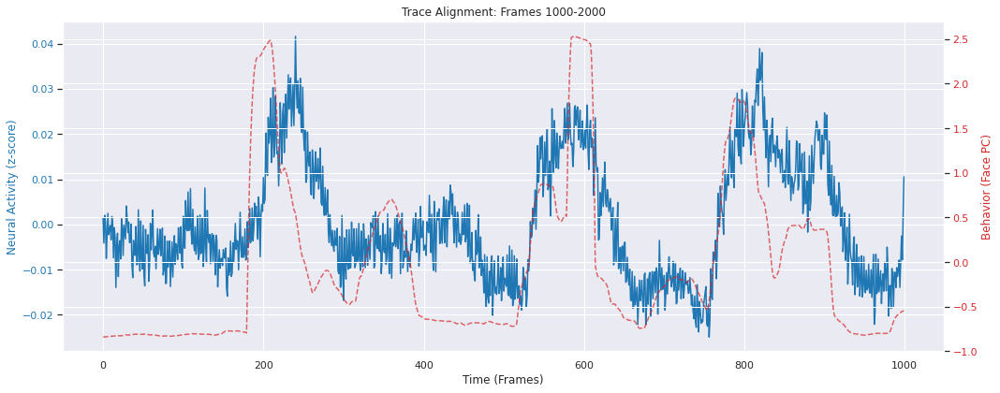

In [367]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pick a representative session (e.g., the first one)
session_id = all_sessions[0]
session_data = data_joint_filtered.loc[session_id]

# 2. Select the signals to compare
# Let's look at Thy1 M1 vs Face PC (usually a strong candidate)
neural_idx = 404 + 500        # Thy1 M1
behavior_col = 'log_RFP_vel' # Behavior

neural_trace = session_data.iloc[:, neural_idx]
behavior_trace = session_data[behavior_col]

# 3. Plotting
fig, axes = plt.subplots(1, 1, figsize=(15, 6))

# --- Plot A: Time Series Overlay (Zoomed in) ---
# We only plot a 1000-frame window to see details clearly
start_frame = 1000
end_frame = 2000
window = slice(start_frame, end_frame)

ax1 = axes
color = 'tab:blue'
ax1.set_xlabel('Time (Frames)')
ax1.set_ylabel('Neural Activity (z-score)', color=color)
ax1.plot(neural_trace.iloc[window].values, color=color, label='Neural (Thy1 M1)')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Behavior (Face PC)', color=color)
ax2.plot(behavior_trace.iloc[window].values, color=color, linestyle='--', alpha=0.7, label='Behavior')
ax2.tick_params(axis='y', labelcolor=color)

axes.set_title(f'Trace Alignment: Frames {start_frame}-{end_frame}')

# # --- Plot B: Scatter Plot ---
# # This shows the "shape" of the correlation
# axes[1].scatter(neural_trace, behavior_trace, alpha=0.1, s=2, color='purple')
# axes[1].set_xlabel('Neural Activity')
# axes[1].set_ylabel('Behavior (Face PC)')
# axes[1].set_title(f'Scatter: Correlation r = {neural_trace.corr(behavior_trace):.2f}')

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import MultiTaskLassoCV
from sklearn.metrics import r2_score
def fit_uni_linear_model(X_train,Y_train):
    LCV = MultiTaskLassoCV(alphas=[1e-4, 5e-4, 8e-4,1e-3, 2e-3, 5e-3, 1e-2],cv=5,n_jobs=-1,tol=1e-4,max_iter=2000).fit(X_train, Y_train)
    return LCV


In [27]:
vel_col_idx = 0  # Index of face_pc in behavior_cols (used for balancing)

In [28]:
# Extract neural activity and behaviors
Thy1_data = data_joint_filtered.iloc[:, :500]      
CSNs_data = data_joint_filtered.iloc[:, 500:1000]  
behavior_data = data_joint_filtered[behavior_cols] 
all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))



def get_data_split_timeseries(X, Y, train_size_value=0.6):
    """Split time series data chronologically without shuffling"""
    n_samples = X.shape[0]
    split_idx = int(n_samples * train_size_value)
    
    X_train = X[:split_idx]
    X_test = X[split_idx:]
    Y_train = Y[:split_idx]
    Y_test = Y[split_idx:]
    
    return X_train, X_test, Y_train, Y_test

def get_balanced_train_data(X_train, y_train, target_col_idx):
    """
    Balances data based on user-defined thresholds:
    Rest: < -0.5
    Run: > -0.5
    """
    # 1. Get the target variable (face_pc)
    target_vals = y_train[:, target_col_idx]
    
    # 2. Identify indices for your specific states
    idx_rest = np.where(target_vals < -0.5)[0]
    idx_run  = np.where(target_vals > -0.5)[0]
    idx_mid  = np.where((target_vals >= -0.5) & (target_vals <= -0.5))[0] # Transition data
    
    # 3. Determine sample size (match the minority group)
    # We assume Rest is the minority. If Run is smaller, this handles it too.
    n_samples = min(len(idx_rest), len(idx_run))
    
    # Safety check: if one state is missing, return original data
    if n_samples < 10: 
        print("Warning: One state has too few samples to balance. Using original data.")
        return X_train, y_train

    # 4. Downsample both groups to the same size
    # (Usually we keep all of the minority, but using random choice on both is cleaner code)
    idx_rest_bal = np.random.choice(idx_rest, size=n_samples, replace=False)
    idx_run_bal  = np.random.choice(idx_run,  size=n_samples, replace=False)
    
    # 5. Combine: Balanced Rest + Balanced Run + All Transition Data
    # We keep 'idx_mid' to help the model learn the linear slope between states
    keep_indices = np.concatenate([idx_rest_bal, idx_run_bal, idx_mid])
    
    # 6. Shuffle indices (crucial for LassoCV to see mixed batches)
    np.random.shuffle(keep_indices)
    
    return X_train[keep_indices], y_train[keep_indices]

# ==========================================
# Main Training Loop
# ==========================================
print("="*50)
print("Training with Balanced Subsampling (Flat Velocity Distribution)")
print("="*50)

session_data_thy1 = {}
session_data_csns = {}

X_train_thy1_list = []
y_train_thy1_list = []
X_train_csns_list = []
y_train_csns_list = []

for session in all_sessions:
    # --- Thy1 Data Prep ---
    X_thy1 = Thy1_data.loc[session].values
    y_thy1 = behavior_data.loc[session].values
    
    # 1. Chronological Split
    Xt_train, Xt_test, yt_train, yt_test = get_data_split_timeseries(X_thy1, y_thy1)
    
    # 2. BALANCE the Training Data (The Magic Step)
    # We re-sample the training set so 'Rest' and 'Run' are equally represented
    Xt_train_bal, yt_train_bal = get_balanced_train_data(Xt_train, yt_train, target_col_idx=vel_col_idx)

    # Store for global training
    X_train_thy1_list.append(Xt_train_bal)
    y_train_thy1_list.append(yt_train_bal)
    
    # Store test sets for evaluation (Keep these UNTOUCHED/UNBALANCED)
    session_data_thy1[session] = {'X_test': Xt_test, 'y_test': yt_test}

    # --- CSNs Data Prep ---
    X_csns = CSNs_data.loc[session].values
    y_csns = behavior_data.loc[session].values
    
    # 1. Chronological Split
    Xc_train, Xc_test, yc_train, yc_test = get_data_split_timeseries(X_csns, y_csns)
    
    # 2. BALANCE the Training Data
    Xc_train_bal, yc_train_bal = get_balanced_train_data(Xc_train, yc_train, target_col_idx=vel_col_idx)
    
    X_train_csns_list.append(Xc_train_bal)
    y_train_csns_list.append(yc_train_bal)
    
    session_data_csns[session] = {'X_test': Xc_test, 'y_test': yc_test}

# Concatenate all balanced training data
X_train_thy1 = np.vstack(X_train_thy1_list)
y_train_thy1 = np.vstack(y_train_thy1_list)
X_train_csns = np.vstack(X_train_csns_list)
y_train_csns = np.vstack(y_train_csns_list)

print(f"\nThy1 Balanced Train: X={X_train_thy1.shape} (Downsampled from original)")
print(f"CSNs Balanced Train: X={X_train_csns.shape}")

# === Train Models ===
print("\nTraining Thy1 Model (Balanced)...")
thy1_model = fit_uni_linear_model(X_train_thy1, y_train_thy1)

print("Training CSNs Model (Balanced)...")
csns_model = fit_uni_linear_model(X_train_csns, y_train_csns)

# === Evaluate on Original (Unbalanced) Test Data ===
thy1_scores = []
csns_scores = []

for session in all_sessions:
    # Thy1 Test
    Xt_test = session_data_thy1[session]['X_test']
    yt_test = session_data_thy1[session]['y_test']
    y_pred_thy1 = thy1_model.predict(Xt_test)
    thy1_scores.append(r2_score(yt_test, y_pred_thy1, multioutput='raw_values'))
    
    # CSNs Test
    Xc_test = session_data_csns[session]['X_test']
    yc_test = session_data_csns[session]['y_test']
    y_pred_csns = csns_model.predict(Xc_test)
    csns_scores.append(r2_score(yc_test, y_pred_csns, multioutput='raw_values'))

# Reporting
thy1_scores = np.array(thy1_scores)
csns_scores = np.array(csns_scores)

print("\n" + "="*50)
print("Test Set R2 Scores (Evaluated on Real Distribution)")
print("="*50)
print(f"Behaviors: {behavior_cols}")
print(f"Thy1 Mean R2: {thy1_scores.mean(axis=0)}")
print(f"CSNs Mean R2: {csns_scores.mean(axis=0)}")

Training with Balanced Subsampling (Flat Velocity Distribution)

Thy1 Balanced Train: X=(142230, 500) (Downsampled from original)
CSNs Balanced Train: X=(142230, 500)

Training Thy1 Model (Balanced)...
Training CSNs Model (Balanced)...

Test Set R2 Scores (Evaluated on Real Distribution)
Behaviors: ['face_pc', 'body_pc', 'RFP_vel']
Thy1 Mean R2: [ 0.40408161 -0.27403265 -2.56989641]
CSNs Mean R2: [ 0.32036932 -0.27795011 -2.666607  ]


Plotting session: cm229_10_runC


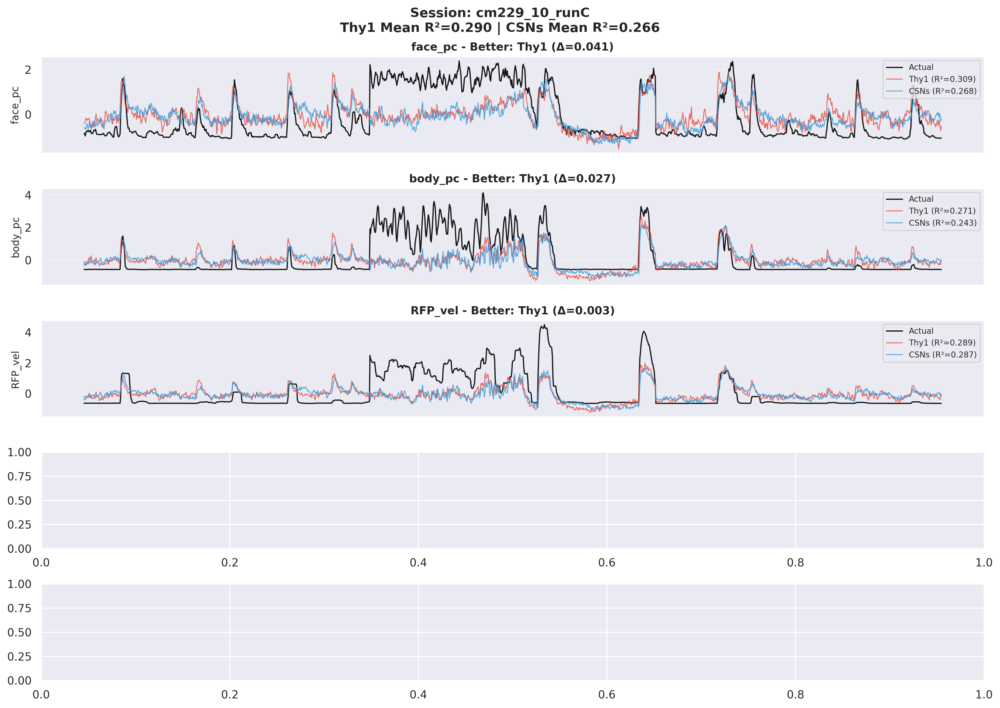


Finding Best and Worst Sessions


AttributeError: 'list' object has no attribute 'mean'

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

def plot_session_predictions(session_name, t_range=None, figsize=(14, 10)):
    """
    Plot predictions vs actual for a specific session, comparing Thy1 and CSNs models.
    
    Parameters:
    -----------
    session_name : str
        Name of the session to plot (e.g., 'cm229_6_runD')
    t_range : array-like, optional
        Specific time points to plot. If None, plots sample of test data
    """
    
    # Get test data for this session
    X_test_thy1 = session_data_thy1[session_name]['X_test']
    y_test = session_data_thy1[session_name]['y_test']
    X_test_csns = session_data_csns[session_name]['X_test']
    
    # Get predictions
    y_pred_thy1 = thy1_model.predict(X_test_thy1)
    y_pred_csns = csns_model.predict(X_test_csns)
    
    # If no time range specified, create a sample
    if t_range is None:
        total_points = len(y_test)
        if total_points > 3000:
            # Sample different chunks
            chunk1 = np.arange(0, min(500, total_points))
            chunk2 = np.arange(1000, min(1500, total_points))
            chunk3 = np.arange(2000, min(2500, total_points))
            t_range = np.concatenate([chunk1, chunk2, chunk3])
            t_range = t_range[t_range < total_points]
        else:
            t_range = np.arange(total_points)
    
    # Time axis (assuming 20 Hz sampling)
    t_ax = np.arange(len(t_range)) / 20.0
    
    # Calculate R² scores for this session
    r2_thy1 = r2_score(y_test, y_pred_thy1, multioutput='raw_values')
    r2_csns = r2_score(y_test, y_pred_csns, multioutput='raw_values')
    
    # Create figure
    fig, axes = plt.subplots(5, 1, figsize=figsize, dpi=300)
    
    for i, behavior in enumerate(behavior_cols):
        ax = axes[i]
        
        # Plot predictions and actual
        ax.plot(t_ax, y_test[t_range, i], 
                label='Actual', linewidth=1.2, alpha=0.9, color='black')
        ax.plot(t_ax, y_pred_thy1[t_range, i], 
                label=f'Thy1 (R²={r2_thy1[i]:.3f})', linewidth=0.9, alpha=0.8, color='#E74C3C')
        ax.plot(t_ax, y_pred_csns[t_range, i], 
                label=f'CSNs (R²={r2_csns[i]:.3f})', linewidth=0.9, alpha=0.8, color='#3498DB')
        
        # Formatting
        if i < 4:
            ax.set_xticks([])
        else:
            ax.set_xlabel('Time (s)', fontsize=10)
        
        ax.set_ylabel(behavior, fontsize=10)
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, alpha=0.3)
        
        # Title with comparison
        diff = r2_thy1[i] - r2_csns[i]
        winner = "Thy1" if diff > 0 else "CSNs"
        ax.set_title(f'{behavior} - Better: {winner} (Δ={abs(diff):.3f})', fontsize=11, fontweight='bold')
    
    plt.suptitle(f'Session: {session_name}\nThy1 Mean R²={r2_thy1.mean():.3f} | CSNs Mean R²={r2_csns.mean():.3f}', 
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    
    return fig, r2_thy1, r2_csns


# === Example 1: Plot a specific session ===
# Choose a session to examine
example_session = all_sessions[0]  # Change index to examine different sessions
print(f"Plotting session: {example_session}")

fig, r2_thy1, r2_csns = plot_session_predictions(example_session)
plt.show()

# === Example 2: Find and plot best/worst sessions ===
print("\n" + "="*50)
print("Finding Best and Worst Sessions")
print("="*50)

# Calculate mean test R² for each session
session_thy1_means = thy1_session_scores_test.mean(axis=1)
session_csns_means = csns_session_scores_test.mean(axis=1)

# Find best and worst sessions for each model
best_thy1_idx = np.argmax(session_thy1_means)
worst_thy1_idx = np.argmin(session_thy1_means)
best_csns_idx = np.argmax(session_csns_means)
worst_csns_idx = np.argmin(session_csns_means)

print(f"\nBest Thy1 session: {all_sessions[best_thy1_idx]} (R²={session_thy1_means[best_thy1_idx]:.3f})")
print(f"Worst Thy1 session: {all_sessions[worst_thy1_idx]} (R²={session_thy1_means[worst_thy1_idx]:.3f})")
print(f"\nBest CSNs session: {all_sessions[best_csns_idx]} (R²={session_csns_means[best_csns_idx]:.3f})")
print(f"Worst CSNs session: {all_sessions[worst_csns_idx]} (R²={session_csns_means[worst_csns_idx]:.3f})")

# Plot best session for Thy1
fig1, _, _ = plot_session_predictions(all_sessions[best_thy1_idx])
plt.savefig(f'best_thy1_session.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot worst session for Thy1
fig2, _, _ = plot_session_predictions(all_sessions[worst_thy1_idx])
plt.savefig(f'worst_thy1_session.png', dpi=300, bbox_inches='tight')
plt.show()

# === Example 3: Find sessions where Thy1 >> CSNs or CSNs >> Thy1 ===
print("\n" + "="*50)
print("Sessions with Largest Model Differences")
print("="*50)

differences = session_thy1_means - session_csns_means

# Thy1 much better than CSNs
thy1_wins_idx = np.argsort(differences)[-5:][::-1]  # Top 5
print("\nTop 5 sessions where Thy1 >> CSNs:")
for idx in thy1_wins_idx:
    print(f"  {all_sessions[idx]}: Thy1={session_thy1_means[idx]:.3f}, CSNs={session_csns_means[idx]:.3f}, Diff={differences[idx]:.3f}")

# CSNs much better than Thy1
csns_wins_idx = np.argsort(differences)[:5]  # Bottom 5
print("\nTop 5 sessions where CSNs >> Thy1:")
for idx in csns_wins_idx:
    print(f"  {all_sessions[idx]}: Thy1={session_thy1_means[idx]:.3f}, CSNs={session_csns_means[idx]:.3f}, Diff={differences[idx]:.3f}")

# Plot the session with biggest Thy1 advantage
fig3, _, _ = plot_session_predictions(all_sessions[thy1_wins_idx[0]])
plt.savefig(f'thy1_much_better_session.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot the session with biggest CSNs advantage
fig4, _, _ = plot_session_predictions(all_sessions[csns_wins_idx[0]])
plt.savefig(f'csns_much_better_session.png', dpi=300, bbox_inches='tight')
plt.show()

# === Example 4: Plot specific behavior across sessions ===
def plot_behavior_across_models(behavior_name='face_pc'):
    """Compare Thy1 vs CSNs performance for a specific behavior across all sessions"""
    behavior_idx = behavior_cols.index(behavior_name)
    
    thy1_scores = thy1_session_scores_test[:, behavior_idx]
    csns_scores = csns_session_scores_test[:, behavior_idx]
    
    plt.figure(figsize=(12, 6), dpi=300)
    
    # Scatter plot
    plt.subplot(1, 2, 1)
    plt.scatter(thy1_scores, csns_scores, alpha=0.6, s=50)
    plt.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Unity line')
    plt.xlabel('Thy1 R²', fontsize=12)
    plt.ylabel('CSNs R²', fontsize=12)
    plt.title(f'{behavior_name}: Thy1 vs CSNs\nAcross All Sessions', fontsize=13, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    # Bar plot comparison
    plt.subplot(1, 2, 2)
    x = np.arange(len(all_sessions))
    width = 0.35
    plt.bar(x - width/2, thy1_scores, width, label='Thy1', alpha=0.8, color='#E74C3C')
    plt.bar(x + width/2, csns_scores, width, label='CSNs', alpha=0.8, color='#3498DB')
    plt.xlabel('Session Index', fontsize=12)
    plt.ylabel('R² Score', fontsize=12)
    plt.title(f'{behavior_name}: Per-Session Comparison', fontsize=13, fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig(f'{behavior_name}_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n{behavior_name} Statistics:")
    print(f"  Thy1: {thy1_scores.mean():.3f} ± {thy1_scores.std():.3f}")
    print(f"  CSNs: {csns_scores.mean():.3f} ± {csns_scores.std():.3f}")
    print(f"  Thy1 wins in {(thy1_scores > csns_scores).sum()}/{len(all_sessions)} sessions")

# Plot each behavior
for behavior in behavior_cols:
    plot_behavior_across_models(behavior)

In [31]:
import numpy as np
import pandas as pd

# ==========================================
# 1. Setup & Helper Functions
# ==========================================
behavior_cols = ['face_pc', 'body_pc', 'RFP_vel']

# Select balancing target (0 = face_pc)
bal_target_idx = 0 

def get_data_split_timeseries(X, Y, train_size_value=0.6):
    """Split time series chronologically"""
    n_samples = X.shape[0]
    split_idx = int(n_samples * train_size_value)
    return X[:split_idx], X[split_idx:], Y[:split_idx], Y[split_idx:]

def get_balanced_train_data_custom(X_train, y_train, target_col_idx):
    """
    Balances data based on user-defined thresholds:
    Rest: < -0.5 | Run: > 0.5
    """
    target_vals = y_train[:, target_col_idx]
    
    # Identify indices
    idx_rest = np.where(target_vals < -0.5)[0]
    idx_run  = np.where(target_vals > -0.50)[0]
    idx_mid  = np.where((target_vals >= -0.5) & (target_vals <= -0.50))[0] 
    
    # Determine sample size (match minority)
    if len(idx_rest) == 0 or len(idx_run) == 0:
        return X_train, y_train # Fallback
        
    n_samples = min(len(idx_rest), len(idx_run))
    
    # Downsample
    idx_rest_bal = np.random.choice(idx_rest, size=n_samples, replace=False)
    idx_run_bal  = np.random.choice(idx_run,  size=n_samples, replace=False)
    
    # Combine & Shuffle
    keep_indices = np.concatenate([idx_rest_bal, idx_run_bal, idx_mid])
    np.random.shuffle(keep_indices)
    
    return X_train[keep_indices], y_train[keep_indices]

# ==========================================
# 2. Build Balanced Training Set
# ==========================================
Thy1_data = data_joint_filtered.iloc[:, :500]      
CSNs_data = data_joint_filtered.iloc[:, 500:1000]  
behavior_data = data_joint_filtered[behavior_cols] 
all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))

X_thy1_bal_list = []
y_thy1_bal_list = []
X_csns_bal_list = []
y_csns_bal_list = []

for session in all_sessions:
    # --- Process Thy1 ---
    X_t = Thy1_data.loc[session].values
    y_t = behavior_data.loc[session].values
    Xt_train, _, yt_train, _ = get_data_split_timeseries(X_t, y_t)
    
    # Balance Thy1
    Xt_bal, yt_bal = get_balanced_train_data_custom(Xt_train, yt_train, bal_target_idx)
    X_thy1_bal_list.append(Xt_bal)
    y_thy1_bal_list.append(yt_bal)

    # --- Process CSNs ---
    X_c = CSNs_data.loc[session].values
    # y_c is same as y_t
    Xc_train, _, yc_train, _ = get_data_split_timeseries(X_c, y_t)
    
    # Balance CSNs
    Xc_bal, yc_bal = get_balanced_train_data_custom(Xc_train, yc_train, bal_target_idx)
    X_csns_bal_list.append(Xc_bal)
    y_csns_bal_list.append(yc_bal)

# Concatenate all sessions
X_thy1_final = np.vstack(X_thy1_bal_list)
y_thy1_final = np.vstack(y_thy1_bal_list)
X_csns_final = np.vstack(X_csns_bal_list)
y_csns_final = np.vstack(y_csns_bal_list)

# ==========================================
# 3. Calculate Correlations for Channel 322
# ==========================================
target_channel = 322

# Extract Channel 322 Activity
neuron_thy1_322 = X_thy1_final[:, target_channel]
neuron_csns_322 = X_csns_final[:, target_channel]

print(f"{'='*60}")
print(f"CORRELATION ANALYSIS: Channel {target_channel} (Balanced Data)")
print(f"{'='*60}")
print(f"{'Dataset':<10} | {'Behavior':<10} | {'Correlation (r)':<15}")
print("-" * 45)

# Calculate and Print Thy1 Correlations
for i, beh in enumerate(behavior_cols):
    r = np.corrcoef(neuron_thy1_322, y_thy1_final[:, i])[0, 1]
    print(f"{'Thy1':<10} | {beh:<10} | {r:.4f}")

print("-" * 45)

# Calculate and Print CSNs Correlations
for i, beh in enumerate(behavior_cols):
    r = np.corrcoef(neuron_csns_322, y_csns_final[:, i])[0, 1]
    print(f"{'CSNs':<10} | {beh:<10} | {r:.4f}")
print("-" * 45)



CORRELATION ANALYSIS: Channel 322 (Balanced Data)
Dataset    | Behavior   | Correlation (r)
---------------------------------------------
Thy1       | face_pc    | 0.5336
Thy1       | body_pc    | 0.5367
Thy1       | RFP_vel    | 0.4289
---------------------------------------------
CSNs       | face_pc    | 0.4804
CSNs       | body_pc    | 0.4662
CSNs       | RFP_vel    | 0.3934
---------------------------------------------


In [42]:
import numpy as np
import pandas as pd

# ==========================================
# 1. Setup & Helper Functions
# ==========================================
behavior_cols = ['face_pc', 'body_pc', 'RFP_vel']
target_channel = 413
bal_target_idx = 0  # 0 = face_pc

def get_data_split_timeseries(X, Y, train_size_value=0.6):
    """Split time series chronologically"""
    n_samples = X.shape[0]
    split_idx = int(n_samples * train_size_value)
    return X[:split_idx], X[split_idx:], Y[:split_idx], Y[split_idx:]

def get_balanced_train_data_custom(X_train, y_train, target_col_idx):
    """
    Balances data: Rest (< -0.5) matched to Run (> 0.5)
    """
    target_vals = y_train[:, target_col_idx]
    
    idx_rest = np.where(target_vals < -0.5)[0]
    idx_run  = np.where(target_vals > 0.5)[0]
    idx_mid  = np.where((target_vals >= -0.5) & (target_vals <= 0.5))[0] 
    
    if len(idx_rest) == 0 or len(idx_run) == 0:
        return X_train, y_train 
        
    n_samples = min(len(idx_rest), len(idx_run))
    
    idx_rest_bal = np.random.choice(idx_rest, size=n_samples, replace=False)
    idx_run_bal  = np.random.choice(idx_run,  size=n_samples, replace=False)
    
    keep_indices = np.concatenate([idx_rest_bal, idx_run_bal, idx_mid])
    np.random.shuffle(keep_indices)
    
    return X_train[keep_indices], y_train[keep_indices]

# ==========================================
# 2. Build Datasets (Unbalanced & Balanced)
# ==========================================
Thy1_data = data_joint_filtered.iloc[:, :500]      
CSNs_data = data_joint_filtered.iloc[:, 500:1000]  
behavior_data = data_joint_filtered[behavior_cols] 
all_sessions = list(np.unique(data_joint_filtered.index.get_level_values(0)))

# lists for Unbalanced
X_thy1_unbal_list, y_thy1_unbal_list = [], []
X_csns_unbal_list, y_csns_unbal_list = [], []

# lists for Balanced
X_thy1_bal_list, y_thy1_bal_list = [], []
X_csns_bal_list, y_csns_bal_list = [], []

for session in all_sessions:
    # --- Thy1 ---
    X_t = Thy1_data.loc[session].values
    y_t = behavior_data.loc[session].values
    Xt_train, _, yt_train, _ = get_data_split_timeseries(X_t, y_t)
    
    # Store Unbalanced
    X_thy1_unbal_list.append(Xt_train)
    y_thy1_unbal_list.append(yt_train)
    
    # Store Balanced
    Xt_bal, yt_bal = get_balanced_train_data_custom(Xt_train, yt_train, bal_target_idx)
    X_thy1_bal_list.append(Xt_bal)
    y_thy1_bal_list.append(yt_bal)

    # --- CSNs ---
    X_c = CSNs_data.loc[session].values
    Xc_train, _, yc_train, _ = get_data_split_timeseries(X_c, y_t)
    
    # Store Unbalanced
    X_csns_unbal_list.append(Xc_train)
    y_csns_unbal_list.append(yc_train)

    # Store Balanced
    Xc_bal, yc_bal = get_balanced_train_data_custom(Xc_train, yc_train, bal_target_idx)
    X_csns_bal_list.append(Xc_bal)
    y_csns_bal_list.append(yc_bal)

# Stack everything
X_thy1_unbal = np.vstack(X_thy1_unbal_list)
y_thy1_unbal = np.vstack(y_thy1_unbal_list)
X_thy1_bal   = np.vstack(X_thy1_bal_list)
y_thy1_bal   = np.vstack(y_thy1_bal_list)

X_csns_unbal = np.vstack(X_csns_unbal_list)
y_csns_unbal = np.vstack(y_csns_unbal_list)
X_csns_bal   = np.vstack(X_csns_bal_list)
y_csns_bal   = np.vstack(y_csns_bal_list)

# ==========================================
# 3. Compute & Compare Correlations
# ==========================================
results = []

def get_corrs(X, y, dataset_name):
    neuron_data = X[:, target_channel]
    corrs = []
    for i, beh in enumerate(behavior_cols):
        r = np.corrcoef(neuron_data, y[:, i])[0, 1]
        corrs.append(r)
    return corrs

# Calculate all 4 sets of correlations
thy1_unbal_corr = get_corrs(X_thy1_unbal, y_thy1_unbal, "Thy1 Unbal")
thy1_bal_corr   = get_corrs(X_thy1_bal, y_thy1_bal, "Thy1 Bal")
csns_unbal_corr = get_corrs(X_csns_unbal, y_csns_unbal, "CSNs Unbal")
csns_bal_corr   = get_corrs(X_csns_bal, y_csns_bal, "CSNs Bal")

# Create DataFrame for display
df_compare = pd.DataFrame({
    'Behavior': behavior_cols,
    'Thy1 (Unbalanced)': thy1_unbal_corr,
    'Thy1 (Balanced)': thy1_bal_corr,
    'Thy1 (Change)': np.array(thy1_bal_corr) - np.array(thy1_unbal_corr),
    'CSNs (Unbalanced)': csns_unbal_corr,
    'CSNs (Balanced)': csns_bal_corr,
    'CSNs (Change)': np.array(csns_bal_corr) - np.array(csns_unbal_corr)
})

print(f"\n{'='*80}")
print(f"CORRELATION COMPARISON: Channel {target_channel}")
print(f"Unbalanced (Original) vs Balanced (Rest matched to Run)")
print(f"{'='*80}")
print(df_compare.to_string(index=False, float_format="%.4f"))
print(f"{'='*80}")

# Quick Interpretation check
print("\nInterpretation:")
print("If 'Change' is POSITIVE -> Balancing made the neuron LOOK MORE correlated.")
print("If 'Change' is NEGATIVE -> The high correlation was driven mostly by the 'Run' state abundance.")


CORRELATION COMPARISON: Channel 413
Unbalanced (Original) vs Balanced (Rest matched to Run)
Behavior  Thy1 (Unbalanced)  Thy1 (Balanced)  Thy1 (Change)  CSNs (Unbalanced)  CSNs (Balanced)  CSNs (Change)
 face_pc             0.3289           0.3411         0.0122             0.5488           0.5443        -0.0045
 body_pc             0.3785           0.3945         0.0160             0.4798           0.4757        -0.0041
 RFP_vel             0.3057           0.3175         0.0117             0.4475           0.4442        -0.0032

Interpretation:
If 'Change' is POSITIVE -> Balancing made the neuron LOOK MORE correlated.
If 'Change' is NEGATIVE -> The high correlation was driven mostly by the 'Run' state abundance.


In [35]:
# === Evaluate on Each Session ===
print("\nEvaluating on Each Session...")

thy1_session_scores_train = []
thy1_session_scores_test = []
csns_session_scores_train = []
csns_session_scores_test = []

session_results = []

for session in all_sessions:
    # === Thy1 evaluation ===
    X_train = session_data_thy1[session]['X_train']
    y_train = session_data_thy1[session]['y_train']
    X_test = session_data_thy1[session]['X_test']
    y_test = session_data_thy1[session]['y_test']
    
    y_pred_train_thy1 = thy1_model.predict(X_train)
    y_pred_test_thy1 = thy1_model.predict(X_test)
    
    thy1_train_r2 = r2_score(y_train, y_pred_train_thy1, multioutput='raw_values')
    thy1_test_r2 = r2_score(y_test, y_pred_test_thy1, multioutput='raw_values')
    
    thy1_session_scores_train.append(thy1_train_r2)
    thy1_session_scores_test.append(thy1_test_r2)
    
    # === CSNs evaluation ===
    X_train = session_data_csns[session]['X_train']
    y_train = session_data_csns[session]['y_train']
    X_test = session_data_csns[session]['X_test']
    y_test = session_data_csns[session]['y_test']
    
    y_pred_train_csns = csns_model.predict(X_train)
    y_pred_test_csns = csns_model.predict(X_test)
    
    csns_train_r2 = r2_score(y_train, y_pred_train_csns, multioutput='raw_values')
    csns_test_r2 = r2_score(y_test, y_pred_test_csns, multioutput='raw_values')
    
    csns_session_scores_train.append(csns_train_r2)
    csns_session_scores_test.append(csns_test_r2)
    
    # Store session results
    session_result = {
        'session': session,
        'thy1_train_mean': thy1_train_r2.mean(),
        'thy1_test_mean': thy1_test_r2.mean(),
        'csns_train_mean': csns_train_r2.mean(),
        'csns_test_mean': csns_test_r2.mean(),
    }
    
    for i, behavior in enumerate(behavior_cols):
        session_result[f'thy1_test_{behavior}'] = thy1_test_r2[i]
        session_result[f'csns_test_{behavior}'] = csns_test_r2[i]
    
    session_results.append(session_result)

# Convert to arrays
thy1_session_scores_train = np.array(thy1_session_scores_train)
thy1_session_scores_test = np.array(thy1_session_scores_test)
csns_session_scores_train = np.array(csns_session_scores_train)
csns_session_scores_test = np.array(csns_session_scores_test)

# === Print Summary ===
print("\n" + "="*50)
print("Summary: Mean ± Std across Sessions (NO SHUFFLE)")
print("="*50)

comparison_table = pd.DataFrame({
    'Behavior': behavior_cols,
    'Thy1_Test_Mean': thy1_session_scores_test.mean(axis=0),
    'Thy1_Test_Std': thy1_session_scores_test.std(axis=0),
    'CSNs_Test_Mean': csns_session_scores_test.mean(axis=0),
    'CSNs_Test_Std': csns_session_scores_test.std(axis=0),
    'Difference (Thy1-CSNs)': thy1_session_scores_test.mean(axis=0) - csns_session_scores_test.mean(axis=0)
})

print(comparison_table.to_string(index=False))

# Update results dictionary
results = {
    'thy1_model': thy1_model,
    'csns_model': csns_model,
    'thy1_session_scores_train': thy1_session_scores_train,
    'thy1_session_scores_test': thy1_session_scores_test,
    'csns_session_scores_train': csns_session_scores_train,
    'csns_session_scores_test': csns_session_scores_test,
    'session_results_df': pd.DataFrame(session_results),
    'comparison_table': comparison_table,
    'behavior_cols': behavior_cols,
    'all_sessions': all_sessions
}

print("\n✓ Models retrained with chronological split!")
print("✓ Now the time series will look correct!")


Evaluating on Each Session...

Summary: Mean ± Std across Sessions (NO SHUFFLE)
Behavior  Thy1_Test_Mean  Thy1_Test_Std  CSNs_Test_Mean  CSNs_Test_Std  Difference (Thy1-CSNs)
 face_pc        0.414848       0.165232        0.344845       0.160659                0.070003
 body_pc       -0.471345       2.986247       -0.431488       2.775990               -0.039858
    rotf      -64.094426     252.665090      -56.041391     224.007215               -8.053035
 RFP_vel       -3.338490      19.246161       -3.290012      19.162473               -0.048478
 LFP_vel       -1.818437       7.863884       -1.609806       7.273919               -0.208631

✓ Models retrained with chronological split!
✓ Now the time series will look correct!


Plotting session: cm229_10_runC


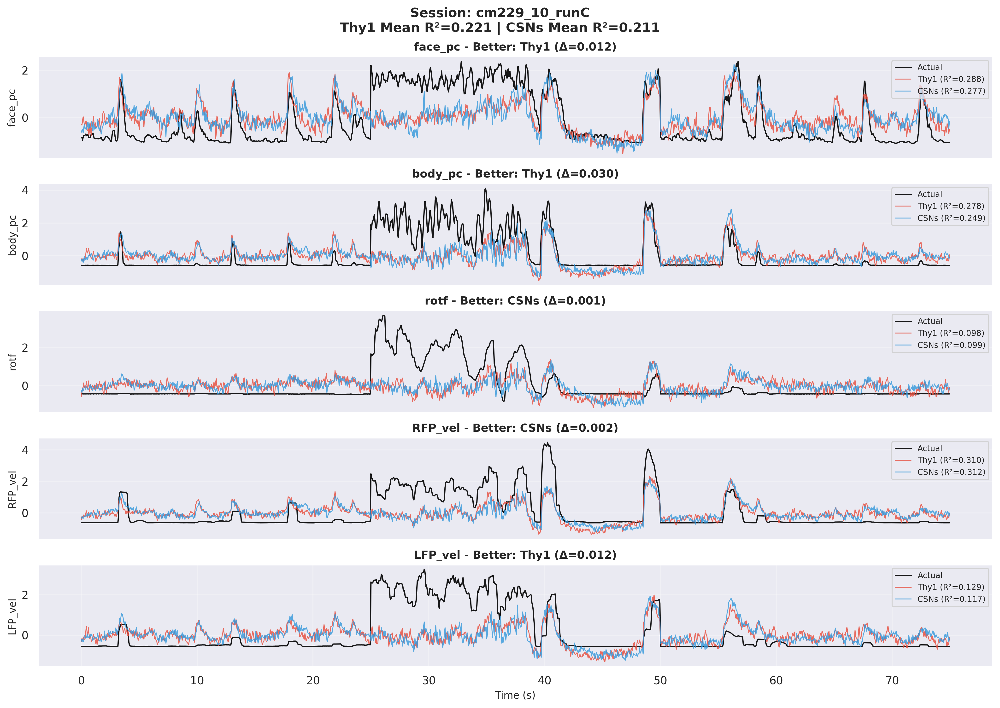


Finding Best and Worst Sessions

Best Thy1 session: cm229_4_runB (R²=0.564)
Worst Thy1 session: cm229_6_runH (R²=-285.318)

Best CSNs session: cm229_4_runC (R²=0.522)
Worst CSNs session: cm229_6_runH (R²=-251.767)


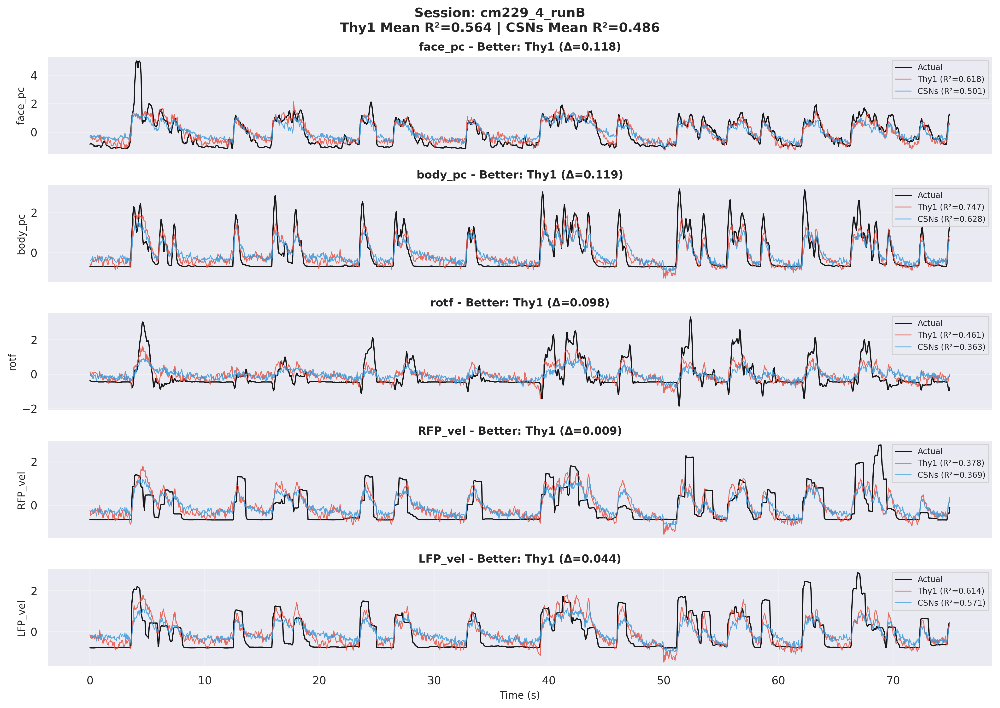

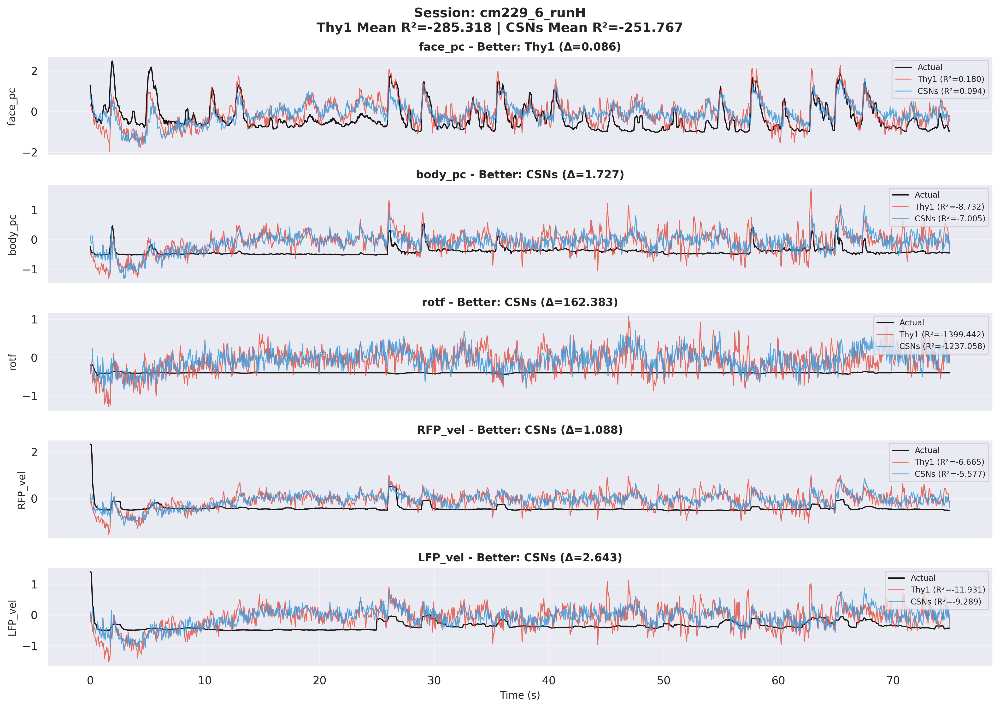


Sessions with Largest Model Differences

Top 5 sessions where Thy1 >> CSNs:
  cm229_1_runG: Thy1=0.495, CSNs=0.411, Diff=0.084
  cm229_10_runI: Thy1=0.083, CSNs=0.002, Diff=0.081
  cm229_4_runB: Thy1=0.564, CSNs=0.486, Diff=0.077
  cm229_6_runI: Thy1=-0.070, CSNs=-0.142, Diff=0.072
  cm229_1_runI: Thy1=0.389, CSNs=0.326, Diff=0.063

Top 5 sessions where CSNs >> Thy1:
  cm229_6_runH: Thy1=-285.318, CSNs=-251.767, Diff=-33.551
  cm229_5_runD: Thy1=-50.883, CSNs=-36.112, Diff=-14.771
  cm229_5_runH: Thy1=-155.457, CSNs=-145.236, Diff=-10.220
  cm229_3_runD: Thy1=-1.396, CSNs=-1.219, Diff=-0.177
  cm229_1_runC: Thy1=0.100, CSNs=0.165, Diff=-0.064


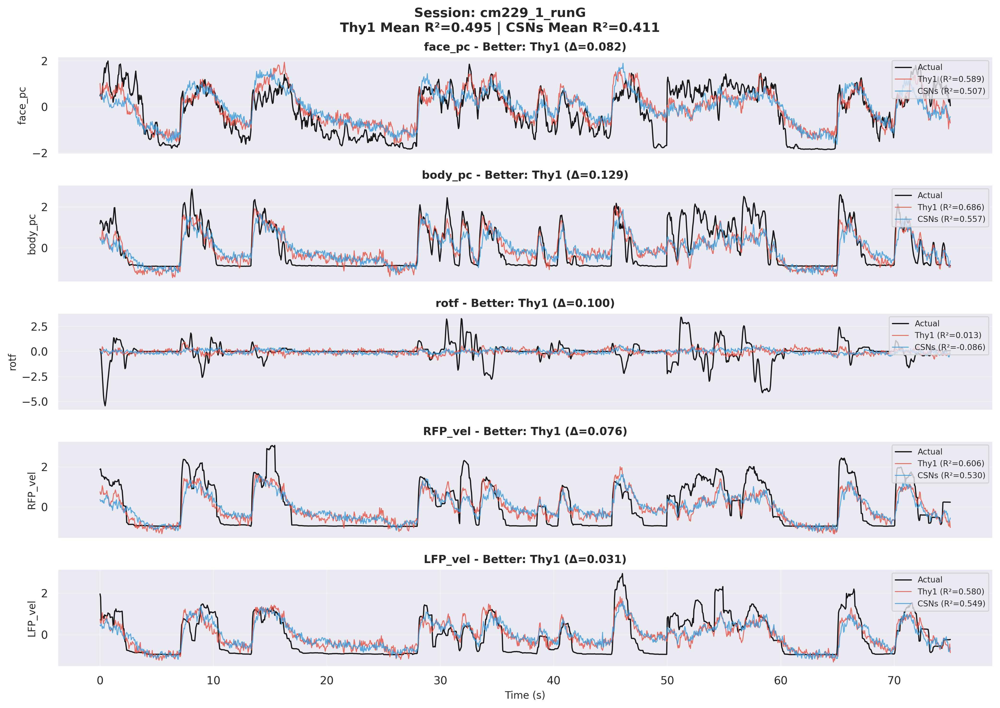

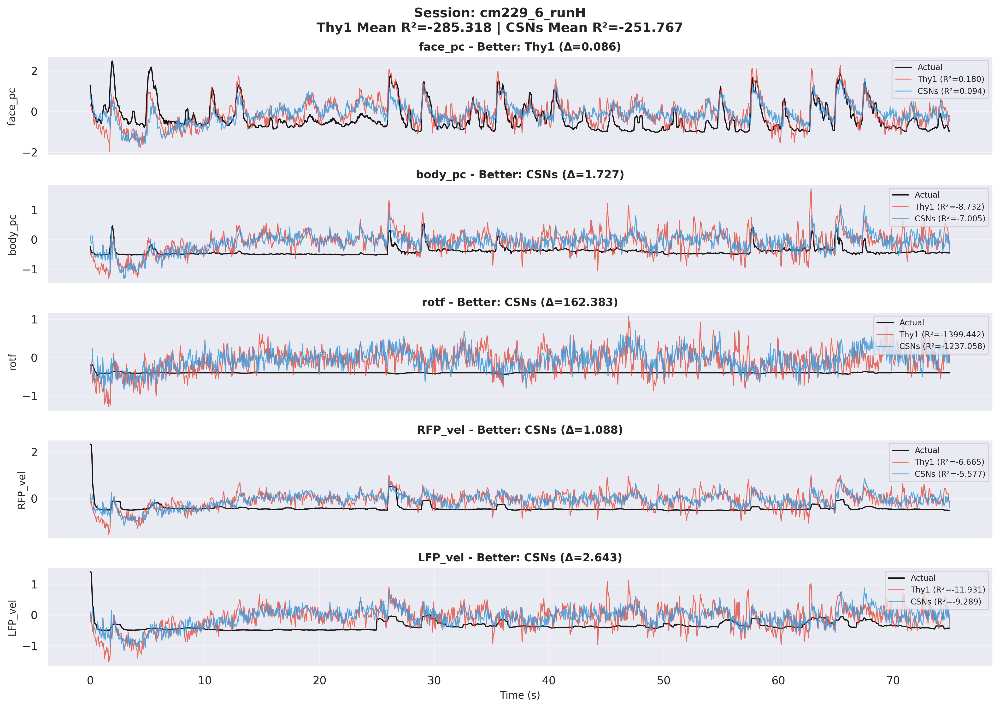

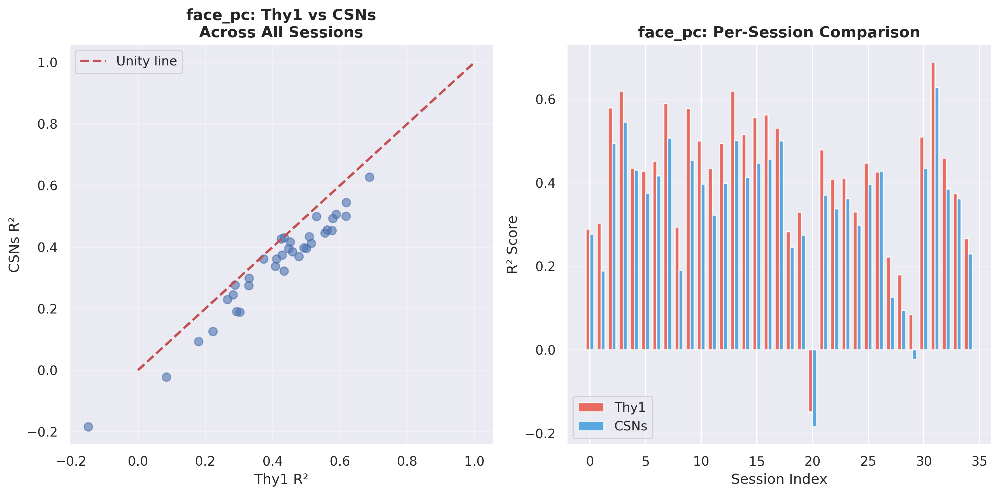


face_pc Statistics:
  Thy1: 0.415 ± 0.165
  CSNs: 0.345 ± 0.161
  Thy1 wins in 34/35 sessions


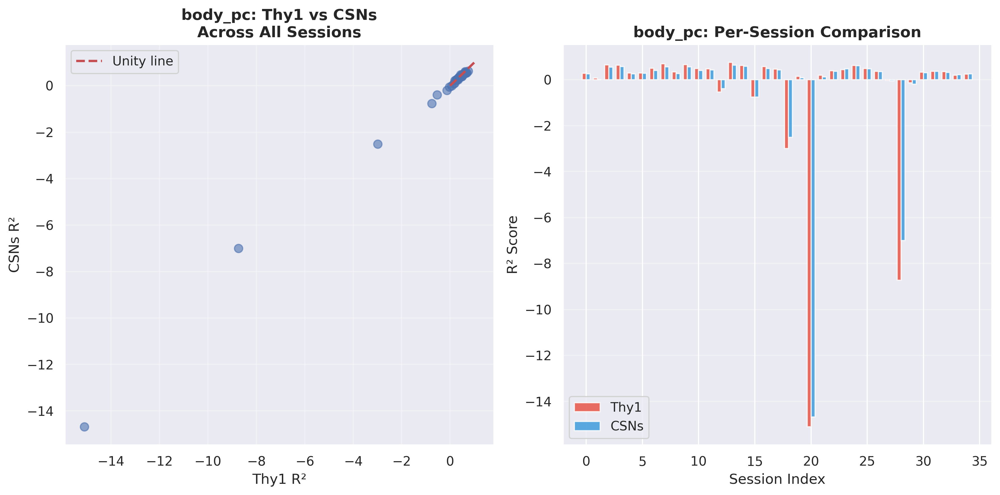


body_pc Statistics:
  Thy1: -0.471 ± 2.986
  CSNs: -0.431 ± 2.776
  Thy1 wins in 27/35 sessions


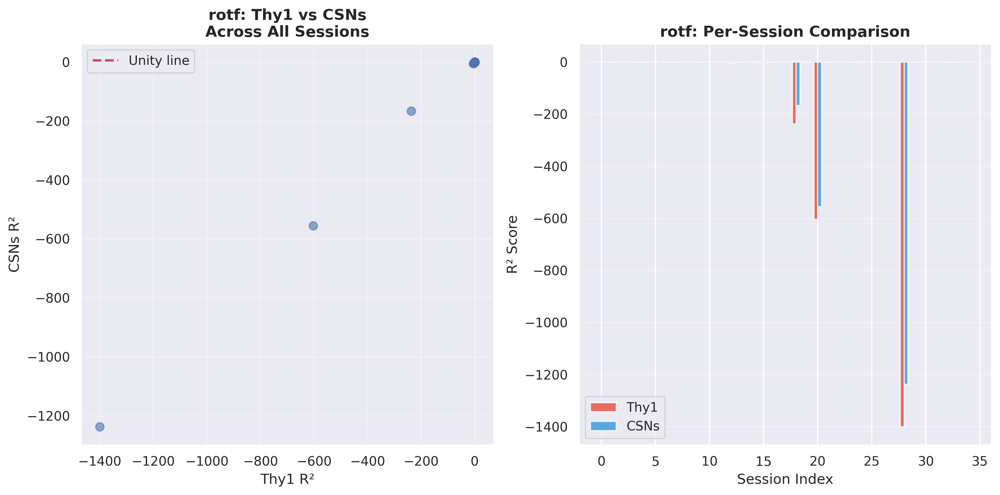


rotf Statistics:
  Thy1: -64.094 ± 252.665
  CSNs: -56.041 ± 224.007
  Thy1 wins in 18/35 sessions


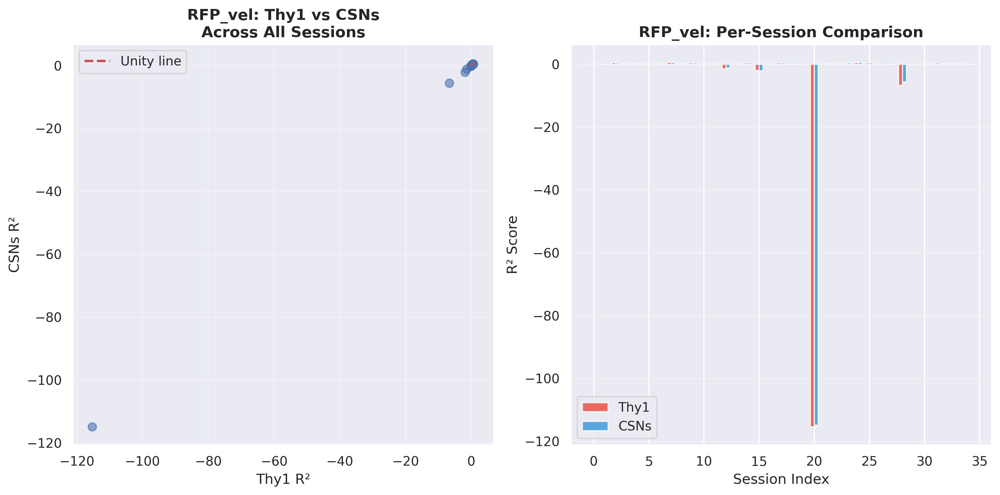


RFP_vel Statistics:
  Thy1: -3.338 ± 19.246
  CSNs: -3.290 ± 19.162
  Thy1 wins in 15/35 sessions


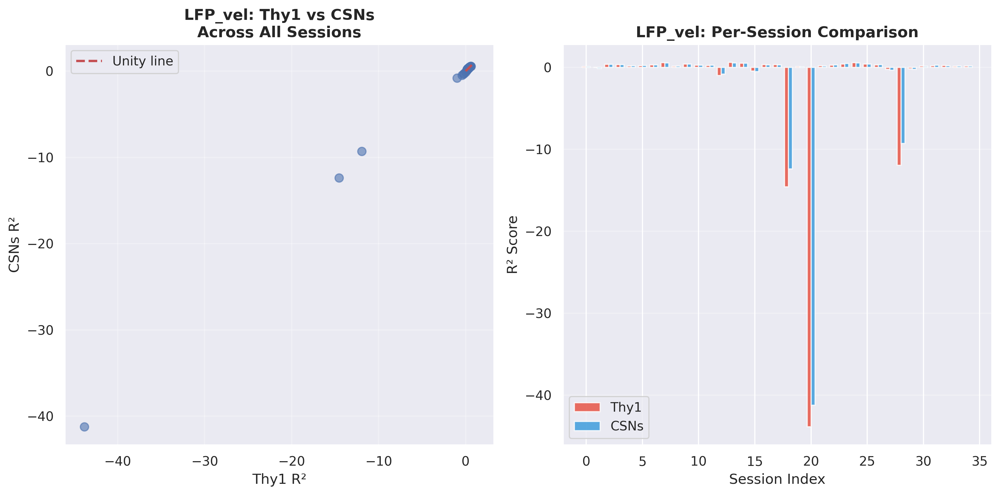


LFP_vel Statistics:
  Thy1: -1.818 ± 7.864
  CSNs: -1.610 ± 7.274
  Thy1 wins in 18/35 sessions


In [36]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

def plot_session_predictions(session_name, t_range=None, figsize=(14, 10)):
    """
    Plot predictions vs actual for a specific session, comparing Thy1 and CSNs models.
    
    Parameters:
    -----------
    session_name : str
        Name of the session to plot (e.g., 'cm229_6_runD')
    t_range : array-like, optional
        Specific time points to plot. If None, plots sample of test data
    """
    
    # Get test data for this session
    X_test_thy1 = session_data_thy1[session_name]['X_test']
    y_test = session_data_thy1[session_name]['y_test']
    X_test_csns = session_data_csns[session_name]['X_test']
    
    # Get predictions
    y_pred_thy1 = thy1_model.predict(X_test_thy1)
    y_pred_csns = csns_model.predict(X_test_csns)
    
    # If no time range specified, create a sample
    if t_range is None:
        total_points = len(y_test)
        if total_points > 3000:
            # Sample different chunks
            chunk1 = np.arange(0, min(500, total_points))
            chunk2 = np.arange(1000, min(1500, total_points))
            chunk3 = np.arange(2000, min(2500, total_points))
            t_range = np.concatenate([chunk1, chunk2, chunk3])
            t_range = t_range[t_range < total_points]
        else:
            t_range = np.arange(total_points)
    
    # Time axis (assuming 20 Hz sampling)
    t_ax = np.arange(len(t_range)) / 20.0
    
    # Calculate R² scores for this session
    r2_thy1 = r2_score(y_test, y_pred_thy1, multioutput='raw_values')
    r2_csns = r2_score(y_test, y_pred_csns, multioutput='raw_values')
    
    # Create figure
    fig, axes = plt.subplots(5, 1, figsize=figsize, dpi=300)
    
    for i, behavior in enumerate(behavior_cols):
        ax = axes[i]
        
        # Plot predictions and actual
        ax.plot(t_ax, y_test[t_range, i], 
                label='Actual', linewidth=1.2, alpha=0.9, color='black')
        ax.plot(t_ax, y_pred_thy1[t_range, i], 
                label=f'Thy1 (R²={r2_thy1[i]:.3f})', linewidth=0.9, alpha=0.8, color='#E74C3C')
        ax.plot(t_ax, y_pred_csns[t_range, i], 
                label=f'CSNs (R²={r2_csns[i]:.3f})', linewidth=0.9, alpha=0.8, color='#3498DB')
        
        # Formatting
        if i < 4:
            ax.set_xticks([])
        else:
            ax.set_xlabel('Time (s)', fontsize=10)
        
        ax.set_ylabel(behavior, fontsize=10)
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, alpha=0.3)
        
        # Title with comparison
        diff = r2_thy1[i] - r2_csns[i]
        winner = "Thy1" if diff > 0 else "CSNs"
        ax.set_title(f'{behavior} - Better: {winner} (Δ={abs(diff):.3f})', fontsize=11, fontweight='bold')
    
    plt.suptitle(f'Session: {session_name}\nThy1 Mean R²={r2_thy1.mean():.3f} | CSNs Mean R²={r2_csns.mean():.3f}', 
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    
    return fig, r2_thy1, r2_csns


# === Example 1: Plot a specific session ===
# Choose a session to examine
example_session = all_sessions[0]  # Change index to examine different sessions
print(f"Plotting session: {example_session}")

fig, r2_thy1, r2_csns = plot_session_predictions(example_session)
plt.show()

# === Example 2: Find and plot best/worst sessions ===
print("\n" + "="*50)
print("Finding Best and Worst Sessions")
print("="*50)

# Calculate mean test R² for each session
session_thy1_means = thy1_session_scores_test.mean(axis=1)
session_csns_means = csns_session_scores_test.mean(axis=1)

# Find best and worst sessions for each model
best_thy1_idx = np.argmax(session_thy1_means)
worst_thy1_idx = np.argmin(session_thy1_means)
best_csns_idx = np.argmax(session_csns_means)
worst_csns_idx = np.argmin(session_csns_means)

print(f"\nBest Thy1 session: {all_sessions[best_thy1_idx]} (R²={session_thy1_means[best_thy1_idx]:.3f})")
print(f"Worst Thy1 session: {all_sessions[worst_thy1_idx]} (R²={session_thy1_means[worst_thy1_idx]:.3f})")
print(f"\nBest CSNs session: {all_sessions[best_csns_idx]} (R²={session_csns_means[best_csns_idx]:.3f})")
print(f"Worst CSNs session: {all_sessions[worst_csns_idx]} (R²={session_csns_means[worst_csns_idx]:.3f})")

# Plot best session for Thy1
fig1, _, _ = plot_session_predictions(all_sessions[best_thy1_idx])
plt.savefig(f'best_thy1_session.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot worst session for Thy1
fig2, _, _ = plot_session_predictions(all_sessions[worst_thy1_idx])
plt.savefig(f'worst_thy1_session.png', dpi=300, bbox_inches='tight')
plt.show()

# === Example 3: Find sessions where Thy1 >> CSNs or CSNs >> Thy1 ===
print("\n" + "="*50)
print("Sessions with Largest Model Differences")
print("="*50)

differences = session_thy1_means - session_csns_means

# Thy1 much better than CSNs
thy1_wins_idx = np.argsort(differences)[-5:][::-1]  # Top 5
print("\nTop 5 sessions where Thy1 >> CSNs:")
for idx in thy1_wins_idx:
    print(f"  {all_sessions[idx]}: Thy1={session_thy1_means[idx]:.3f}, CSNs={session_csns_means[idx]:.3f}, Diff={differences[idx]:.3f}")

# CSNs much better than Thy1
csns_wins_idx = np.argsort(differences)[:5]  # Bottom 5
print("\nTop 5 sessions where CSNs >> Thy1:")
for idx in csns_wins_idx:
    print(f"  {all_sessions[idx]}: Thy1={session_thy1_means[idx]:.3f}, CSNs={session_csns_means[idx]:.3f}, Diff={differences[idx]:.3f}")

# Plot the session with biggest Thy1 advantage
fig3, _, _ = plot_session_predictions(all_sessions[thy1_wins_idx[0]])
plt.savefig(f'thy1_much_better_session.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot the session with biggest CSNs advantage
fig4, _, _ = plot_session_predictions(all_sessions[csns_wins_idx[0]])
plt.savefig(f'csns_much_better_session.png', dpi=300, bbox_inches='tight')
plt.show()

# === Example 4: Plot specific behavior across sessions ===
def plot_behavior_across_models(behavior_name='face_pc'):
    """Compare Thy1 vs CSNs performance for a specific behavior across all sessions"""
    behavior_idx = behavior_cols.index(behavior_name)
    
    thy1_scores = thy1_session_scores_test[:, behavior_idx]
    csns_scores = csns_session_scores_test[:, behavior_idx]
    
    plt.figure(figsize=(12, 6), dpi=300)
    
    # Scatter plot
    plt.subplot(1, 2, 1)
    plt.scatter(thy1_scores, csns_scores, alpha=0.6, s=50)
    plt.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Unity line')
    plt.xlabel('Thy1 R²', fontsize=12)
    plt.ylabel('CSNs R²', fontsize=12)
    plt.title(f'{behavior_name}: Thy1 vs CSNs\nAcross All Sessions', fontsize=13, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    # Bar plot comparison
    plt.subplot(1, 2, 2)
    x = np.arange(len(all_sessions))
    width = 0.35
    plt.bar(x - width/2, thy1_scores, width, label='Thy1', alpha=0.8, color='#E74C3C')
    plt.bar(x + width/2, csns_scores, width, label='CSNs', alpha=0.8, color='#3498DB')
    plt.xlabel('Session Index', fontsize=12)
    plt.ylabel('R² Score', fontsize=12)
    plt.title(f'{behavior_name}: Per-Session Comparison', fontsize=13, fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig(f'{behavior_name}_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n{behavior_name} Statistics:")
    print(f"  Thy1: {thy1_scores.mean():.3f} ± {thy1_scores.std():.3f}")
    print(f"  CSNs: {csns_scores.mean():.3f} ± {csns_scores.std():.3f}")
    print(f"  Thy1 wins in {(thy1_scores > csns_scores).sum()}/{len(all_sessions)} sessions")

# Plot each behavior
for behavior in behavior_cols:
    plot_behavior_across_models(behavior)

# Session specific

In [37]:
print("="*50)
print("Training Session-Specific Models")
print("="*50)

# === Train and evaluate session-specific models ===
session_thy1_models = {}
session_csns_models = {}

thy1_session_scores_train = []
thy1_session_scores_test = []
csns_session_scores_train = []
csns_session_scores_test = []

session_results = []

for i, session in enumerate(all_sessions):
    print(f"\nProcessing session {i+1}/{len(all_sessions)}: {session}")
    
    # Get data for this session
    X_train_thy1 = session_data_thy1[session]['X_train']
    y_train_thy1 = session_data_thy1[session]['y_train']
    X_test_thy1 = session_data_thy1[session]['X_test']
    y_test_thy1 = session_data_thy1[session]['y_test']
    
    X_train_csns = session_data_csns[session]['X_train']
    y_train_csns = session_data_csns[session]['y_train']
    X_test_csns = session_data_csns[session]['X_test']
    y_test_csns = session_data_csns[session]['y_test']
    
    # === Train Thy1 model for this session ===
    thy1_model_session = fit_uni_linear_model(X_train_thy1, y_train_thy1)
    session_thy1_models[session] = thy1_model_session
    
    # Evaluate Thy1 model
    y_pred_train_thy1 = thy1_model_session.predict(X_train_thy1)
    y_pred_test_thy1 = thy1_model_session.predict(X_test_thy1)
    
    thy1_train_r2 = r2_score(y_train_thy1, y_pred_train_thy1, multioutput='raw_values')
    thy1_test_r2 = r2_score(y_test_thy1, y_pred_test_thy1, multioutput='raw_values')
    
    thy1_session_scores_train.append(thy1_train_r2)
    thy1_session_scores_test.append(thy1_test_r2)
    
    # === Train CSNs model for this session ===
    csns_model_session = fit_uni_linear_model(X_train_csns, y_train_csns)
    session_csns_models[session] = csns_model_session
    
    # Evaluate CSNs model
    y_pred_train_csns = csns_model_session.predict(X_train_csns)
    y_pred_test_csns = csns_model_session.predict(X_test_csns)
    
    csns_train_r2 = r2_score(y_train_csns, y_pred_train_csns, multioutput='raw_values')
    csns_test_r2 = r2_score(y_test_csns, y_pred_test_csns, multioutput='raw_values')
    
    csns_session_scores_train.append(csns_train_r2)
    csns_session_scores_test.append(csns_test_r2)
    
    # Store results
    session_result = {
        'session': session,
        'thy1_train_mean': thy1_train_r2.mean(),
        'thy1_test_mean': thy1_test_r2.mean(),
        'csns_train_mean': csns_train_r2.mean(),
        'csns_test_mean': csns_test_r2.mean(),
        'thy1_alpha': thy1_model_session.alpha_,
        'csns_alpha': csns_model_session.alpha_,
    }
    
    # Add individual behavior scores
    for j, behavior in enumerate(behavior_cols):
        session_result[f'thy1_train_{behavior}'] = thy1_train_r2[j]
        session_result[f'thy1_test_{behavior}'] = thy1_test_r2[j]
        session_result[f'csns_train_{behavior}'] = csns_train_r2[j]
        session_result[f'csns_test_{behavior}'] = csns_test_r2[j]
    
    session_results.append(session_result)
    
    print(f"  Thy1: Train R²={thy1_train_r2.mean():.3f}, Test R²={thy1_test_r2.mean():.3f}, α={thy1_model_session.alpha_:.6f}")
    print(f"  CSNs: Train R²={csns_train_r2.mean():.3f}, Test R²={csns_test_r2.mean():.3f}, α={csns_model_session.alpha_:.6f}")

# Convert to arrays
thy1_session_scores_train = np.array(thy1_session_scores_train)
thy1_session_scores_test = np.array(thy1_session_scores_test)
csns_session_scores_train = np.array(csns_session_scores_train)
csns_session_scores_test = np.array(csns_session_scores_test)

# === Summary Statistics ===
print("\n" + "="*50)
print("Summary: Mean ± Std across Sessions (SESSION-SPECIFIC MODELS)")
print("="*50)

comparison_table = pd.DataFrame({
    'Behavior': behavior_cols,
    'Thy1_Test_Mean': thy1_session_scores_test.mean(axis=0),
    'Thy1_Test_Std': thy1_session_scores_test.std(axis=0),
    'CSNs_Test_Mean': csns_session_scores_test.mean(axis=0),
    'CSNs_Test_Std': csns_session_scores_test.std(axis=0),
    'Difference (Thy1-CSNs)': thy1_session_scores_test.mean(axis=0) - csns_session_scores_test.mean(axis=0)
})

print(comparison_table.to_string(index=False))

print(f"\n{'Overall Mean':15s} - Thy1 Train: {thy1_session_scores_train.mean():.4f} ± {thy1_session_scores_train.std():.4f}")
print(f"{'':15s}   Thy1 Test:  {thy1_session_scores_test.mean():.4f} ± {thy1_session_scores_test.std():.4f}")
print(f"{'':15s}   CSNs Train: {csns_session_scores_train.mean():.4f} ± {csns_session_scores_train.std():.4f}")
print(f"{'':15s}   CSNs Test:  {csns_session_scores_test.mean():.4f} ± {csns_session_scores_test.std():.4f}")

# Create detailed results dataframe
session_results_df = pd.DataFrame(session_results)

# === Analysis: Which model wins for each session? ===
print("\n" + "="*50)
print("Session-by-Session Winner Analysis")
print("="*50)

session_means_thy1 = thy1_session_scores_test.mean(axis=1)
session_means_csns = csns_session_scores_test.mean(axis=1)
differences = session_means_thy1 - session_means_csns

thy1_wins = (differences > 0).sum()
csns_wins = (differences < 0).sum()
ties = (differences == 0).sum()

print(f"\nOverall session winners:")
print(f"  Thy1 wins: {thy1_wins}/{len(all_sessions)} sessions ({100*thy1_wins/len(all_sessions):.1f}%)")
print(f"  CSNs wins: {csns_wins}/{len(all_sessions)} sessions ({100*csns_wins/len(all_sessions):.1f}%)")
print(f"  Ties:      {ties}/{len(all_sessions)} sessions")

# Behavior-specific winners
print(f"\nBehavior-specific winners:")
for i, behavior in enumerate(behavior_cols):
    thy1_scores_behavior = thy1_session_scores_test[:, i]
    csns_scores_behavior = csns_session_scores_test[:, i]
    thy1_wins_behavior = (thy1_scores_behavior > csns_scores_behavior).sum()
    csns_wins_behavior = (csns_scores_behavior > thy1_scores_behavior).sum()
    print(f"  {behavior:10s}: Thy1 wins {thy1_wins_behavior}/{len(all_sessions)}, CSNs wins {csns_wins_behavior}/{len(all_sessions)}")

# Update results
results = {
    'session_thy1_models': session_thy1_models,
    'session_csns_models': session_csns_models,
    'thy1_session_scores_train': thy1_session_scores_train,
    'thy1_session_scores_test': thy1_session_scores_test,
    'csns_session_scores_train': csns_session_scores_train,
    'csns_session_scores_test': csns_session_scores_test,
    'session_results_df': session_results_df,
    'comparison_table': comparison_table,
    'behavior_cols': behavior_cols,
    'all_sessions': all_sessions,
    'session_scalers_thy1': session_scalers_thy1,
    'session_scalers_csns': session_scalers_csns
}

print("\n✓ Session-specific models trained!")
print("✓ Each session has its own Thy1 and CSNs model")

Training Session-Specific Models

Processing session 1/35: cm229_10_runC
  Thy1: Train R²=0.319, Test R²=0.207, α=0.005000
  CSNs: Train R²=0.306, Test R²=0.205, α=0.010000

Processing session 2/35: cm229_10_runI
  Thy1: Train R²=0.265, Test R²=-0.064, α=0.002000
  CSNs: Train R²=0.234, Test R²=-0.129, α=0.010000

Processing session 3/35: cm229_11_runD
  Thy1: Train R²=0.459, Test R²=0.486, α=0.005000
  CSNs: Train R²=0.443, Test R²=0.466, α=0.010000

Processing session 4/35: cm229_11_runE
  Thy1: Train R²=0.481, Test R²=0.415, α=0.010000
  CSNs: Train R²=0.458, Test R²=0.425, α=0.010000

Processing session 5/35: cm229_1_runC
  Thy1: Train R²=0.400, Test R²=-0.072, α=0.010000
  CSNs: Train R²=0.397, Test R²=-0.219, α=0.010000

Processing session 6/35: cm229_1_runD
  Thy1: Train R²=0.344, Test R²=0.174, α=0.010000
  CSNs: Train R²=0.348, Test R²=0.151, α=0.010000

Processing session 7/35: cm229_1_runF
  Thy1: Train R²=0.482, Test R²=0.335, α=0.010000
  CSNs: Train R²=0.461, Test R²=0.29


Plotting session: cm229_10_runC with session-specific models


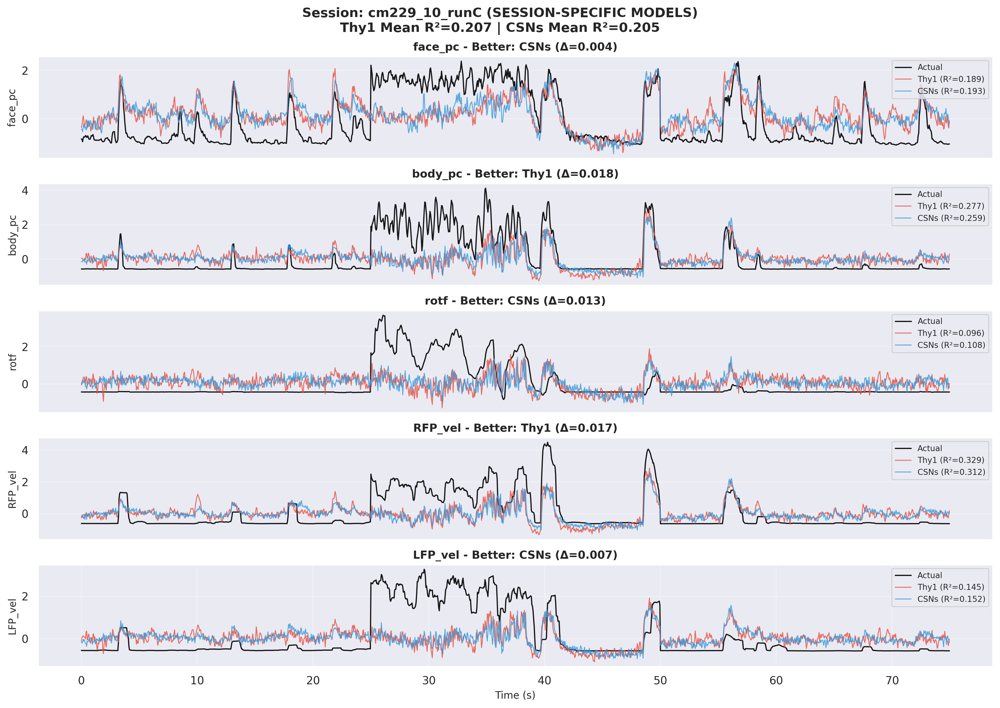

In [38]:
def plot_session_predictions_specific(session_name, t_range=None, figsize=(14, 10)):
    """
    Plot predictions vs actual for a specific session using SESSION-SPECIFIC models.
    """
    
    # Get test data for this session
    X_test_thy1 = session_data_thy1[session_name]['X_test']
    y_test = session_data_thy1[session_name]['y_test']
    X_test_csns = session_data_csns[session_name]['X_test']
    
    # Get predictions using SESSION-SPECIFIC models
    thy1_model_session = session_thy1_models[session_name]
    csns_model_session = session_csns_models[session_name]
    
    y_pred_thy1 = thy1_model_session.predict(X_test_thy1)
    y_pred_csns = csns_model_session.predict(X_test_csns)
    
    # If no time range specified, create a sample
    if t_range is None:
        total_points = len(y_test)
        if total_points > 3000:
            chunk1 = np.arange(0, min(500, total_points))
            chunk2 = np.arange(1000, min(1500, total_points))
            chunk3 = np.arange(2000, min(2500, total_points))
            t_range = np.concatenate([chunk1, chunk2, chunk3])
            t_range = t_range[t_range < total_points]
        else:
            t_range = np.arange(total_points)
    
    # Time axis (assuming 20 Hz sampling)
    t_ax = np.arange(len(t_range)) / 20.0
    
    # Calculate R² scores
    r2_thy1 = r2_score(y_test, y_pred_thy1, multioutput='raw_values')
    r2_csns = r2_score(y_test, y_pred_csns, multioutput='raw_values')
    
    # Create figure
    fig, axes = plt.subplots(5, 1, figsize=figsize, dpi=300)
    
    for i, behavior in enumerate(behavior_cols):
        ax = axes[i]
        
        # Plot predictions and actual
        ax.plot(t_ax, y_test[t_range, i], 
                label='Actual', linewidth=1.2, alpha=0.9, color='black')
        ax.plot(t_ax, y_pred_thy1[t_range, i], 
                label=f'Thy1 (R²={r2_thy1[i]:.3f})', linewidth=0.9, alpha=0.8, color='#E74C3C')
        ax.plot(t_ax, y_pred_csns[t_range, i], 
                label=f'CSNs (R²={r2_csns[i]:.3f})', linewidth=0.9, alpha=0.8, color='#3498DB')
        
        # Formatting
        if i < 4:
            ax.set_xticks([])
        else:
            ax.set_xlabel('Time (s)', fontsize=10)
        
        ax.set_ylabel(behavior, fontsize=10)
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, alpha=0.3)
        
        # Title with comparison
        diff = r2_thy1[i] - r2_csns[i]
        winner = "Thy1" if diff > 0 else "CSNs"
        ax.set_title(f'{behavior} - Better: {winner} (Δ={abs(diff):.3f})', fontsize=11, fontweight='bold')
    
    plt.suptitle(f'Session: {session_name} (SESSION-SPECIFIC MODELS)\nThy1 Mean R²={r2_thy1.mean():.3f} | CSNs Mean R²={r2_csns.mean():.3f}', 
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    
    return fig, r2_thy1, r2_csns

# Plot an example session
example_session = all_sessions[0]
print(f"\nPlotting session: {example_session} with session-specific models")
fig, r2_thy1, r2_csns = plot_session_predictions_specific(example_session)
plt.show()


Plotting session: cm229_11_runE with session-specific models


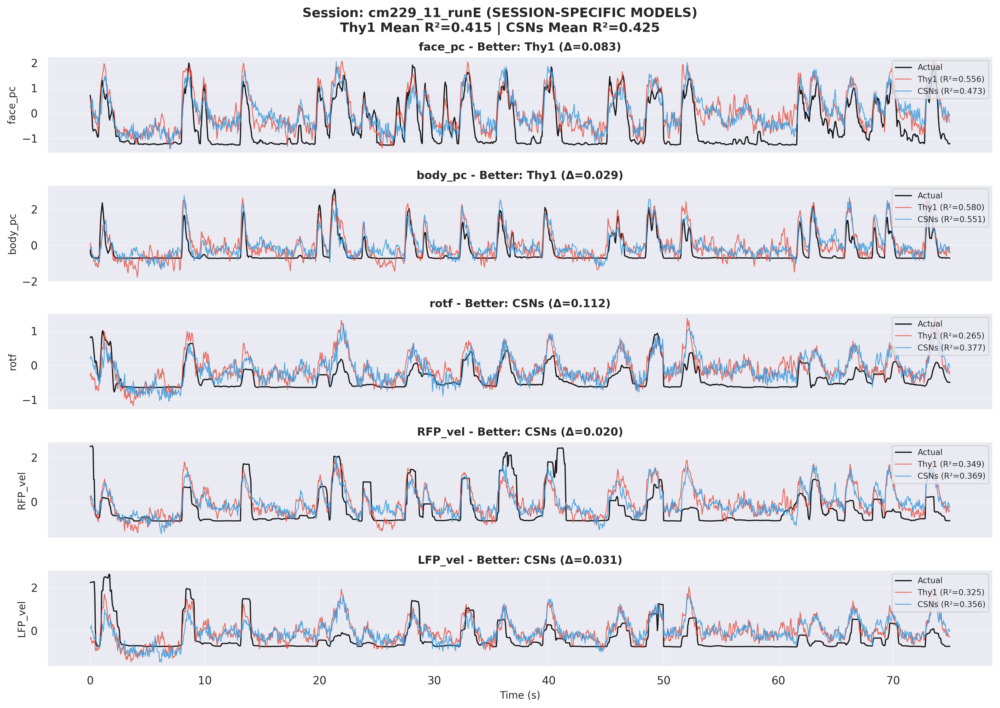

In [39]:

example_session = all_sessions[3]
print(f"\nPlotting session: {example_session} with session-specific models")
fig, r2_thy1, r2_csns = plot_session_predictions_specific(example_session)
plt.show()




# OLD

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import MultiTaskLassoCV
from sklearn.metrics import r2_score

def get_data_split(X,Y,train_size_value=0.6):
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=train_size_value,shuffle=True,
                                                       random_state=7)
    dataDict ={'X_train':X_train,
              'X_test':X_test,
              'y_train':Y_train,
              'y_test':Y_test}
    # print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
    return dataDict


def fit_uni_linear_model(X_train,Y_train):
    LCV = MultiTaskLassoCV(alphas=[1e-4, 5e-4, 8e-4,1e-3, 2e-3, 5e-3, 1e-2],cv=5,n_jobs=-1,tol=1e-9).fit(X_train, Y_train)
    return LCV

In [12]:
# Define behavior columns to predict
behavior_cols = ['face_pc', 'body_pc', 'rotf', 'RFP_vel', 'LFP_vel']

# Extract neural activity and behaviors
Thy1_data = data_joint_filtered.iloc[:, :500]      # First 500 columns
CSNs_data = data_joint_filtered.iloc[:, 500:1000]  # Next 500 columns
behavior_data = data_joint_filtered[behavior_cols]  # 5 behavior columns

print(f"Thy1 shape: {Thy1_data.shape}")
print(f"CSNs shape: {CSNs_data.shape}")
print(f"Behaviors shape: {behavior_data.shape}")

# Get unique sessions
all_sessions = data_joint_filtered.index.get_level_values(0).unique()
print(f"Number of sessions: {len(all_sessions)}")



Thy1 shape: (279055, 500)
CSNs shape: (279055, 500)
Behaviors shape: (279055, 5)
Number of sessions: 35


In [15]:
# === Prepare data for both models ===
session_data_thy1 = {}
session_data_csns = {}

X_train_thy1 = []
y_train_thy1 = []
X_train_csns = []
y_train_csns = []

for session in all_sessions:
    # Get Thy1 data for this session
    X_thy1 = Thy1_data.loc[session].values
    y_thy1 = behavior_data.loc[session].values
    
    # Get CSNs data for this session
    X_csns = CSNs_data.loc[session].values
    y_csns = behavior_data.loc[session].values
    
    # Split Thy1 data
    dataDict_thy1 = get_data_split(X_thy1, y_thy1, train_size_value=0.6)
    session_data_thy1[session] = dataDict_thy1
    X_train_thy1.append(dataDict_thy1['X_train'])
    y_train_thy1.append(dataDict_thy1['y_train'])
    
    # Split CSNs data
    dataDict_csns = get_data_split(X_csns, y_csns, train_size_value=0.6)
    session_data_csns[session] = dataDict_csns
    X_train_csns.append(dataDict_csns['X_train'])
    y_train_csns.append(dataDict_csns['y_train'])

# Concatenate all training data
X_train_thy1 = np.vstack(X_train_thy1)
y_train_thy1 = np.vstack(y_train_thy1)
X_train_csns = np.vstack(X_train_csns)
y_train_csns = np.vstack(y_train_csns)

print(f"\nThy1 Train: X={X_train_thy1.shape}, y={y_train_thy1.shape}")
print(f"CSNs Train: X={X_train_csns.shape}, y={y_train_csns.shape}")



Thy1 Train: X=(167405, 500), y=(167405, 5)
CSNs Train: X=(167405, 500), y=(167405, 5)


In [16]:
# === Train Thy1 Model ===
print("\n" + "="*50)
print("Training Thy1 Model")
print("="*50)

thy1_model = fit_uni_linear_model(X_train_thy1, y_train_thy1)
print(f"Thy1 Model - Best alpha: {thy1_model.alpha_}")

# === Train CSNs Model ===
print("\n" + "="*50)
print("Training CSNs Model")
print("="*50)

csns_model = fit_uni_linear_model(X_train_csns, y_train_csns)
print(f"CSNs Model - Best alpha: {csns_model.alpha_}")

# === Evaluate on Each Session ===
print("\n" + "="*50)
print("Evaluating on Each Session")
print("="*50)

# Store scores for each session
thy1_session_scores_train = []
thy1_session_scores_test = []
csns_session_scores_train = []
csns_session_scores_test = []

session_results = []

for session in all_sessions:
    # === Thy1 evaluation ===
    X_train = session_data_thy1[session]['X_train']
    y_train = session_data_thy1[session]['y_train']
    X_test = session_data_thy1[session]['X_test']
    y_test = session_data_thy1[session]['y_test']
    
    y_pred_train_thy1 = thy1_model.predict(X_train)
    y_pred_test_thy1 = thy1_model.predict(X_test)
    
    thy1_train_r2 = r2_score(y_train, y_pred_train_thy1, multioutput='raw_values')
    thy1_test_r2 = r2_score(y_test, y_pred_test_thy1, multioutput='raw_values')
    
    thy1_session_scores_train.append(thy1_train_r2)
    thy1_session_scores_test.append(thy1_test_r2)
    
    # === CSNs evaluation ===
    X_train = session_data_csns[session]['X_train']
    y_train = session_data_csns[session]['y_train']
    X_test = session_data_csns[session]['X_test']
    y_test = session_data_csns[session]['y_test']
    
    y_pred_train_csns = csns_model.predict(X_train)
    y_pred_test_csns = csns_model.predict(X_test)
    
    csns_train_r2 = r2_score(y_train, y_pred_train_csns, multioutput='raw_values')
    csns_test_r2 = r2_score(y_test, y_pred_test_csns, multioutput='raw_values')
    
    csns_session_scores_train.append(csns_train_r2)
    csns_session_scores_test.append(csns_test_r2)
    
    # Store session results
    session_result = {
        'session': session,
        'thy1_train_mean': thy1_train_r2.mean(),
        'thy1_test_mean': thy1_test_r2.mean(),
        'csns_train_mean': csns_train_r2.mean(),
        'csns_test_mean': csns_test_r2.mean(),
    }
    
    # Add individual behavior scores
    for i, behavior in enumerate(behavior_cols):
        session_result[f'thy1_test_{behavior}'] = thy1_test_r2[i]
        session_result[f'csns_test_{behavior}'] = csns_test_r2[i]
    
    session_results.append(session_result)

# Convert to arrays for easier manipulation
thy1_session_scores_train = np.array(thy1_session_scores_train)  # shape: (n_sessions, n_behaviors)
thy1_session_scores_test = np.array(thy1_session_scores_test)
csns_session_scores_train = np.array(csns_session_scores_train)
csns_session_scores_test = np.array(csns_session_scores_test)




Training Thy1 Model
Thy1 Model - Best alpha: 0.0001

Training CSNs Model
CSNs Model - Best alpha: 0.0001

Evaluating on Each Session


In [17]:
# === Summary Statistics ===
print("\n" + "="*50)
print("Summary: Mean ± Std across Sessions")
print("="*50)

summary_table = pd.DataFrame({
    'Behavior': behavior_cols,
    'Thy1_Train_R2': [f"{thy1_session_scores_train[:, i].mean():.4f} ± {thy1_session_scores_train[:, i].std():.4f}" 
                       for i in range(len(behavior_cols))],
    'Thy1_Test_R2': [f"{thy1_session_scores_test[:, i].mean():.4f} ± {thy1_session_scores_test[:, i].std():.4f}" 
                      for i in range(len(behavior_cols))],
    'CSNs_Train_R2': [f"{csns_session_scores_train[:, i].mean():.4f} ± {csns_session_scores_train[:, i].std():.4f}" 
                       for i in range(len(behavior_cols))],
    'CSNs_Test_R2': [f"{csns_session_scores_test[:, i].mean():.4f} ± {csns_session_scores_test[:, i].std():.4f}" 
                      for i in range(len(behavior_cols))],
})

print(summary_table.to_string(index=False))

# Overall mean
print(f"\n{'Overall Mean':15s} - Thy1 Train: {thy1_session_scores_train.mean():.4f} ± {thy1_session_scores_train.std():.4f}")
print(f"{'':15s}   Thy1 Test:  {thy1_session_scores_test.mean():.4f} ± {thy1_session_scores_test.std():.4f}")
print(f"{'':15s}   CSNs Train: {csns_session_scores_train.mean():.4f} ± {csns_session_scores_train.std():.4f}")
print(f"{'':15s}   CSNs Test:  {csns_session_scores_test.mean():.4f} ± {csns_session_scores_test.std():.4f}")

# === Create detailed results dataframe ===
session_results_df = pd.DataFrame(session_results)

print("\n" + "="*50)
print("Per-Session Results (first 10 sessions)")
print("="*50)
print(session_results_df[['session', 'thy1_test_mean', 'csns_test_mean']].head(10).to_string(index=False))

# === Numeric comparison table (for easier analysis) ===
comparison_table = pd.DataFrame({
    'Behavior': behavior_cols,
    'Thy1_Test_Mean': thy1_session_scores_test.mean(axis=0),
    'Thy1_Test_Std': thy1_session_scores_test.std(axis=0),
    'CSNs_Test_Mean': csns_session_scores_test.mean(axis=0),
    'CSNs_Test_Std': csns_session_scores_test.std(axis=0),
    'Difference (Thy1-CSNs)': thy1_session_scores_test.mean(axis=0) - csns_session_scores_test.mean(axis=0)
})

print("\n" + "="*50)
print("Numeric Comparison Table")
print("="*50)
print(comparison_table.to_string(index=False))

# Save results
results = {
    'thy1_model': thy1_model,
    'csns_model': csns_model,
    'thy1_session_scores_train': thy1_session_scores_train,
    'thy1_session_scores_test': thy1_session_scores_test,
    'csns_session_scores_train': csns_session_scores_train,
    'csns_session_scores_test': csns_session_scores_test,
    'session_results_df': session_results_df,
    'comparison_table': comparison_table,
    'behavior_cols': behavior_cols,
    'all_sessions': all_sessions
}


Summary: Mean ± Std across Sessions
Behavior   Thy1_Train_R2    Thy1_Test_R2   CSNs_Train_R2    CSNs_Test_R2
 face_pc 0.4598 ± 0.1029 0.4603 ± 0.0974 0.3828 ± 0.0928 0.3844 ± 0.0953
 body_pc 0.3922 ± 0.1577 0.3911 ± 0.1565 0.3519 ± 0.1427 0.3496 ± 0.1442
    rotf 0.1871 ± 0.1717 0.1858 ± 0.1695 0.1823 ± 0.1841 0.1764 ± 0.1802
 RFP_vel 0.2933 ± 0.1362 0.2870 ± 0.1347 0.2949 ± 0.1363 0.2880 ± 0.1339
 LFP_vel 0.2878 ± 0.1427 0.2867 ± 0.1416 0.2895 ± 0.1465 0.2871 ± 0.1444

Overall Mean    - Thy1 Train: 0.3240 ± 0.1720
                  Thy1 Test:  0.3222 ± 0.1708
                  CSNs Train: 0.3003 ± 0.1590
                  CSNs Test:  0.2971 ± 0.1589

Per-Session Results (first 10 sessions)
      session  thy1_test_mean  csns_test_mean
cm229_10_runC        0.237621        0.221830
cm229_10_runI        0.177328        0.130296
cm229_11_runD        0.410314        0.387099
cm229_11_runE        0.399530        0.375320
 cm229_1_runC        0.275167        0.263314
 cm229_1_runD        0.

Plotting session: cm229_10_runC


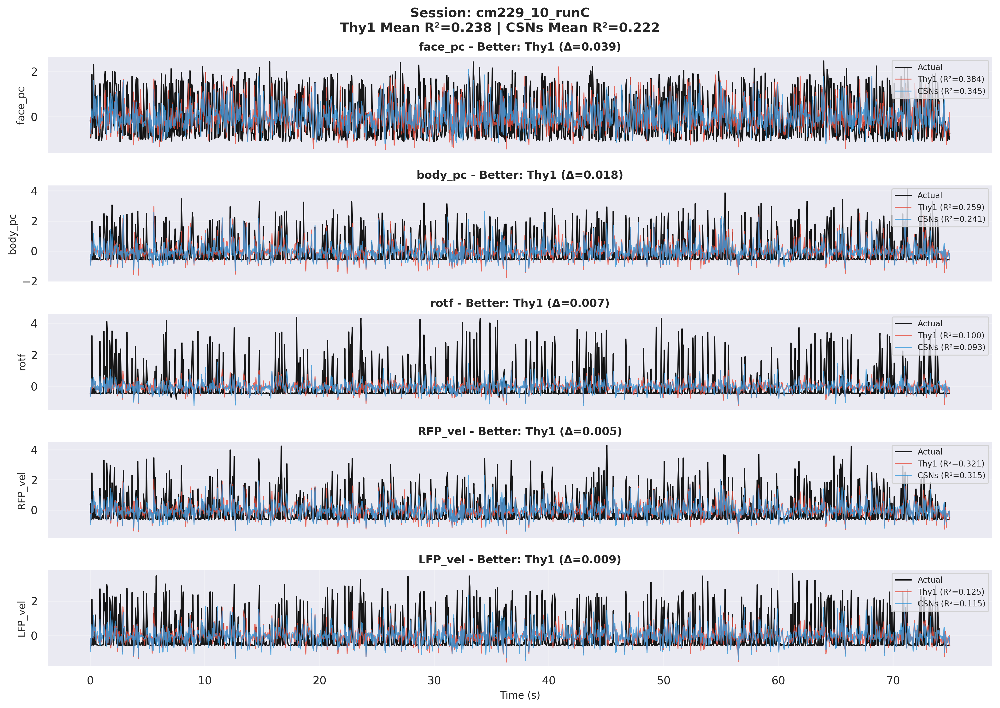


Finding Best and Worst Sessions

Best Thy1 session: cm229_4_runB (R²=0.608)
Worst Thy1 session: cm229_6_runI (R²=0.072)

Best CSNs session: cm229_4_runB (R²=0.570)
Worst CSNs session: cm229_6_runI (R²=0.040)


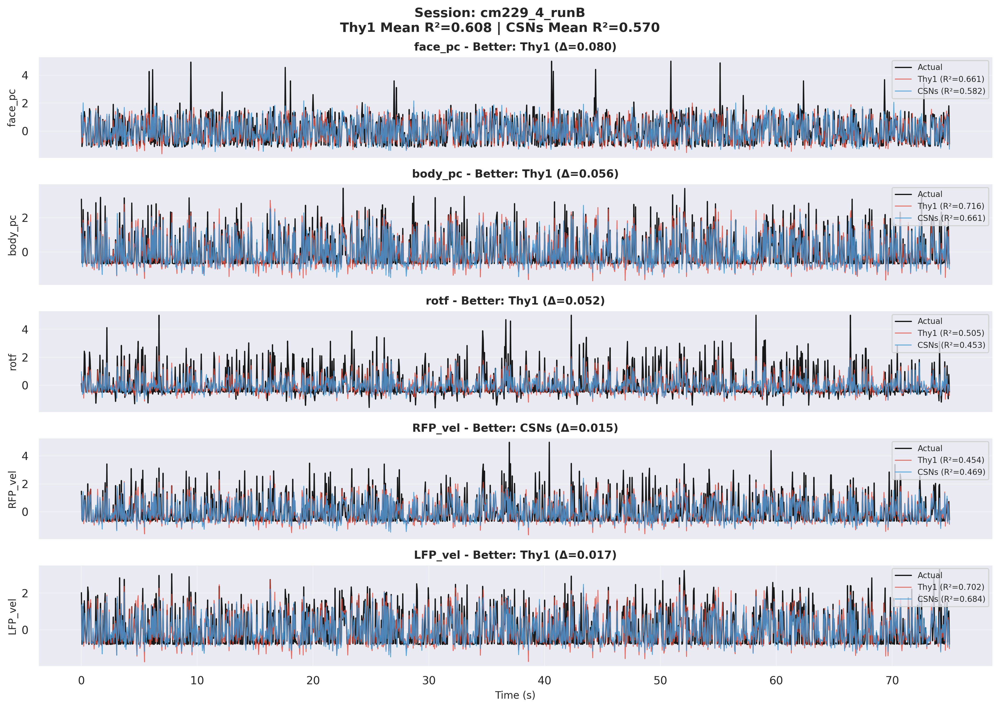

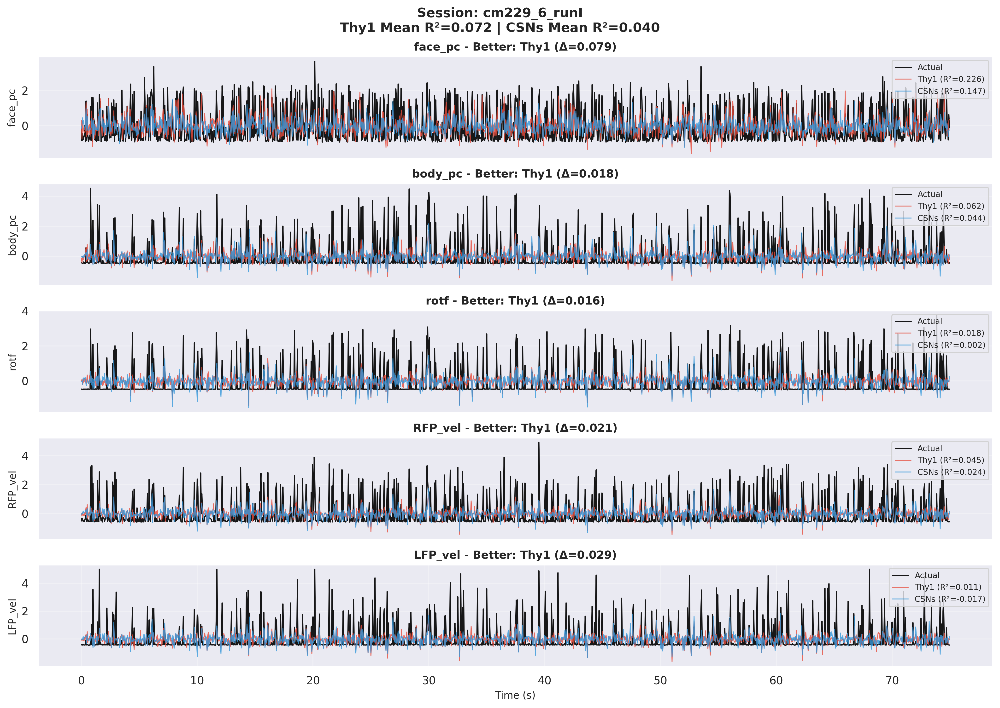


Sessions with Largest Model Differences

Top 5 sessions where Thy1 >> CSNs:
  cm229_1_runG: Thy1=0.441, CSNs=0.372, Diff=0.069
  cm229_5_runC: Thy1=0.424, CSNs=0.363, Diff=0.061
  cm229_1_runI: Thy1=0.298, CSNs=0.239, Diff=0.059
  cm229_10_runI: Thy1=0.177, CSNs=0.130, Diff=0.047
  cm229_5_runI: Thy1=0.173, CSNs=0.126, Diff=0.047

Top 5 sessions where CSNs >> Thy1:
  cm229_6_runC: Thy1=0.400, CSNs=0.420, Diff=-0.020
  cm229_6_runF: Thy1=0.427, CSNs=0.447, Diff=-0.020
  cm229_6_runD: Thy1=0.504, CSNs=0.511, Diff=-0.007
  cm229_8_runD: Thy1=0.206, CSNs=0.207, Diff=-0.000
  cm229_6_runH: Thy1=0.144, CSNs=0.138, Diff=0.005


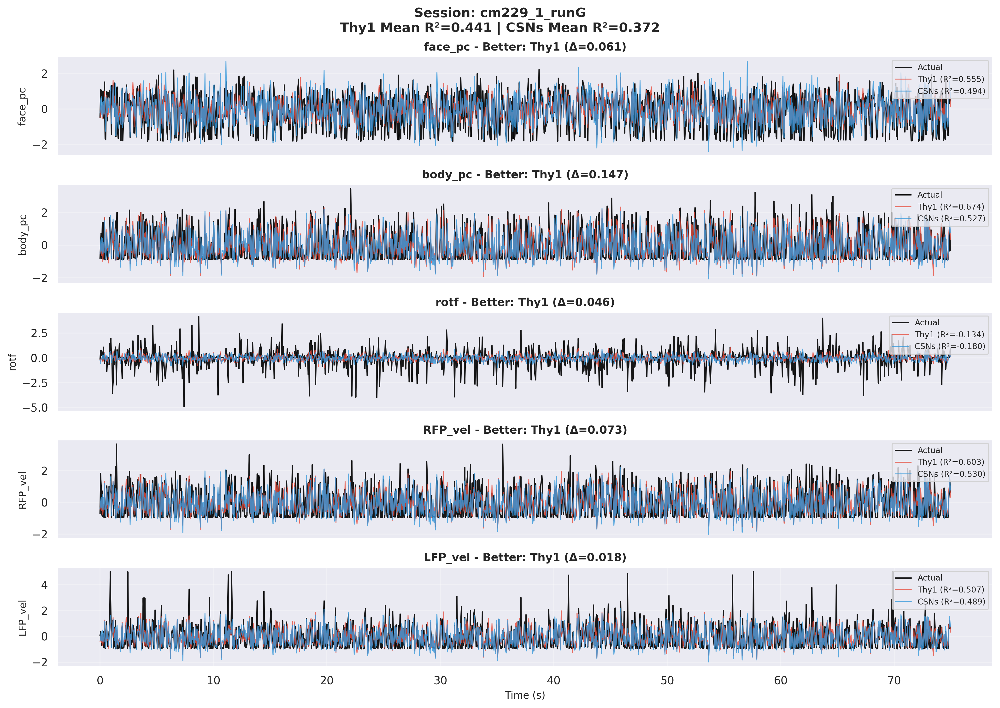

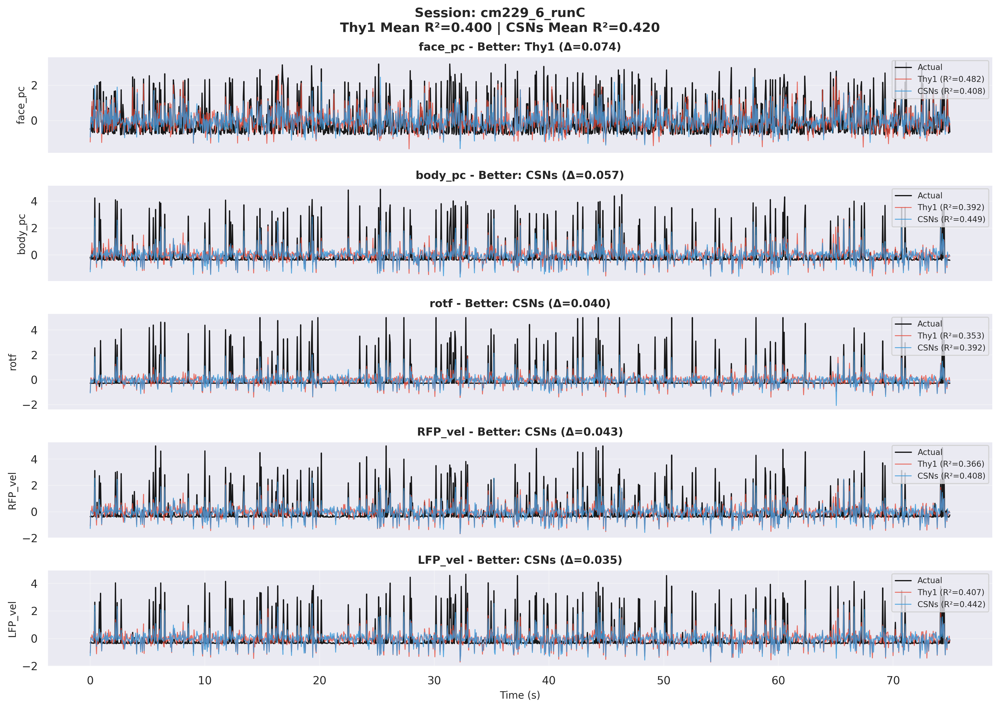

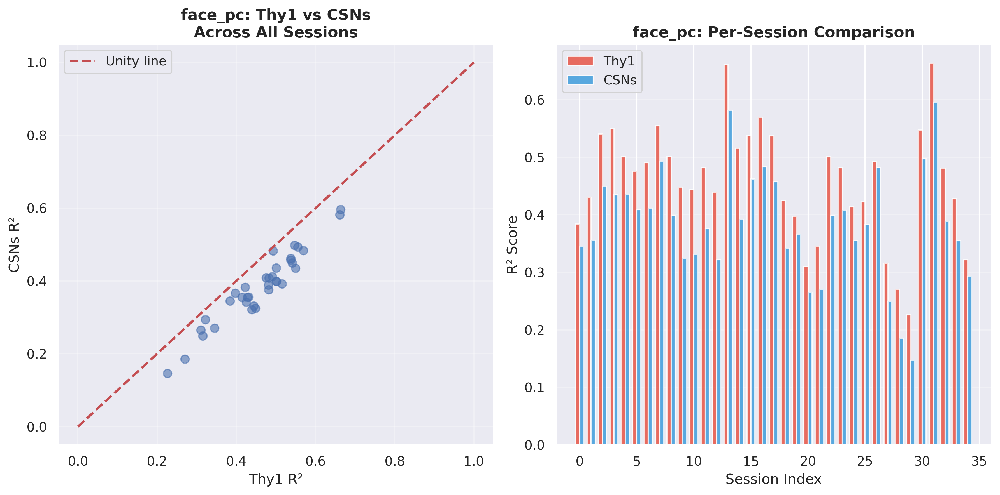


face_pc Statistics:
  Thy1: 0.460 ± 0.097
  CSNs: 0.384 ± 0.095
  Thy1 wins in 35/35 sessions


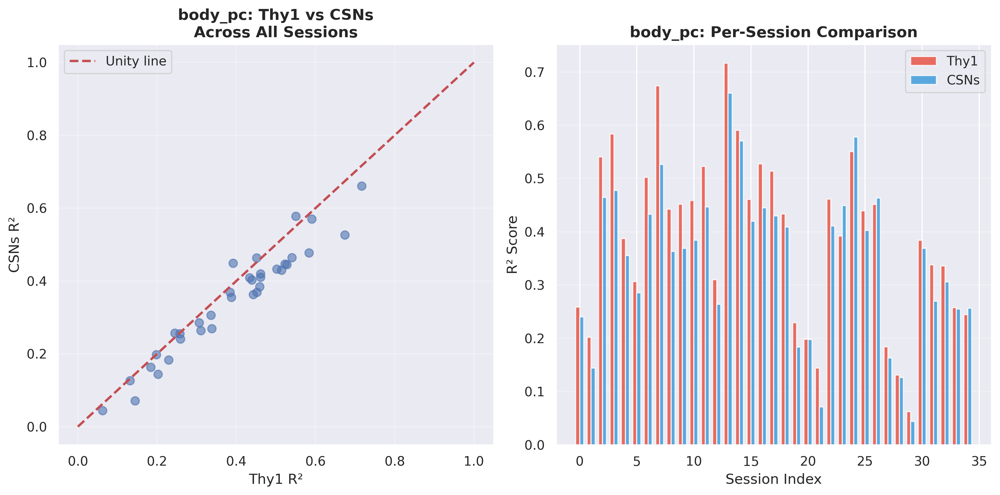


body_pc Statistics:
  Thy1: 0.391 ± 0.157
  CSNs: 0.350 ± 0.144
  Thy1 wins in 31/35 sessions


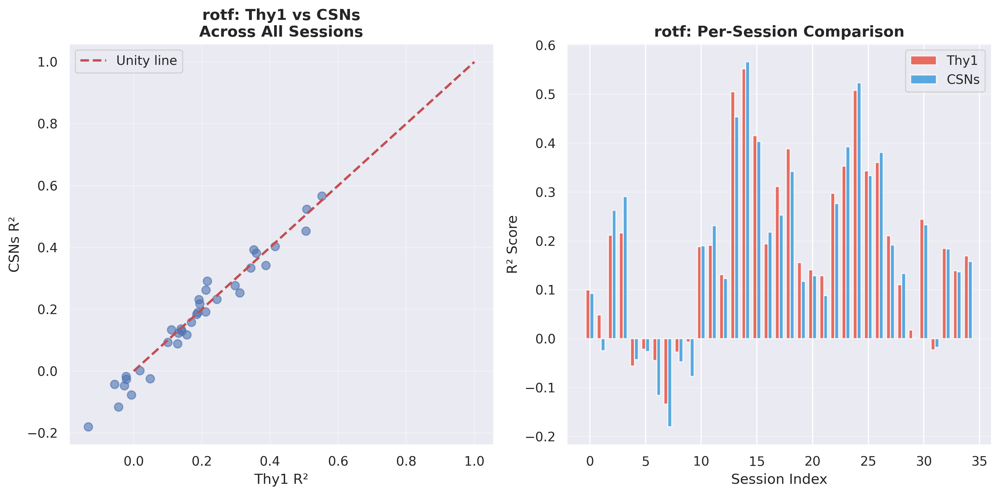


rotf Statistics:
  Thy1: 0.186 ± 0.169
  CSNs: 0.176 ± 0.180
  Thy1 wins in 23/35 sessions


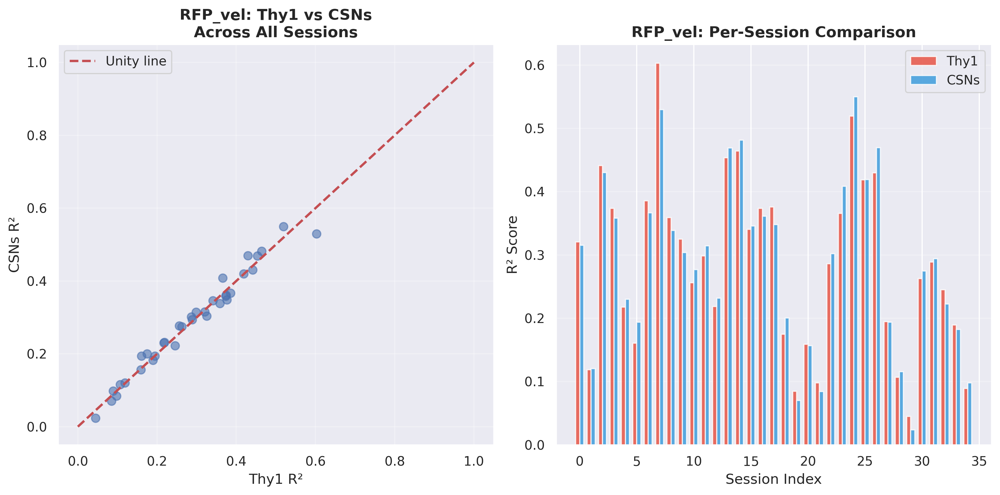


RFP_vel Statistics:
  Thy1: 0.287 ± 0.135
  CSNs: 0.288 ± 0.134
  Thy1 wins in 16/35 sessions


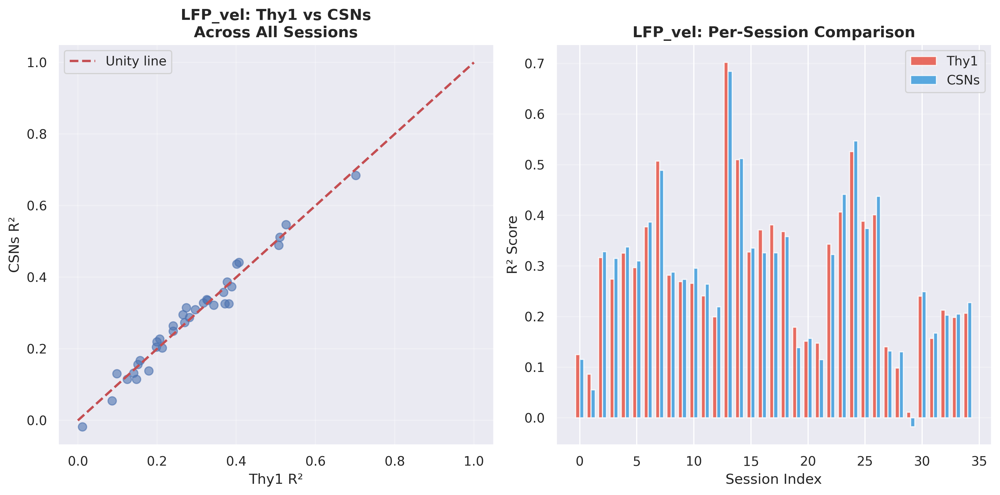


LFP_vel Statistics:
  Thy1: 0.287 ± 0.142
  CSNs: 0.287 ± 0.144
  Thy1 wins in 14/35 sessions


In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

def plot_session_predictions(session_name, t_range=None, figsize=(14, 10)):
    """
    Plot predictions vs actual for a specific session, comparing Thy1 and CSNs models.
    
    Parameters:
    -----------
    session_name : str
        Name of the session to plot (e.g., 'cm229_6_runD')
    t_range : array-like, optional
        Specific time points to plot. If None, plots sample of test data
    """
    
    # Get test data for this session
    X_test_thy1 = session_data_thy1[session_name]['X_test']
    y_test = session_data_thy1[session_name]['y_test']
    X_test_csns = session_data_csns[session_name]['X_test']
    
    # Get predictions
    y_pred_thy1 = thy1_model.predict(X_test_thy1)
    y_pred_csns = csns_model.predict(X_test_csns)
    
    # If no time range specified, create a sample
    if t_range is None:
        total_points = len(y_test)
        if total_points > 3000:
            # Sample different chunks
            chunk1 = np.arange(0, min(500, total_points))
            chunk2 = np.arange(1000, min(1500, total_points))
            chunk3 = np.arange(2000, min(2500, total_points))
            t_range = np.concatenate([chunk1, chunk2, chunk3])
            t_range = t_range[t_range < total_points]
        else:
            t_range = np.arange(total_points)
    
    # Time axis (assuming 20 Hz sampling)
    t_ax = np.arange(len(t_range)) / 20.0
    
    # Calculate R² scores for this session
    r2_thy1 = r2_score(y_test, y_pred_thy1, multioutput='raw_values')
    r2_csns = r2_score(y_test, y_pred_csns, multioutput='raw_values')
    
    # Create figure
    fig, axes = plt.subplots(5, 1, figsize=figsize, dpi=300)
    
    for i, behavior in enumerate(behavior_cols):
        ax = axes[i]
        
        # Plot predictions and actual
        ax.plot(t_ax, y_test[t_range, i], 
                label='Actual', linewidth=1.2, alpha=0.9, color='black')
        ax.plot(t_ax, y_pred_thy1[t_range, i], 
                label=f'Thy1 (R²={r2_thy1[i]:.3f})', linewidth=0.9, alpha=0.8, color='#E74C3C')
        ax.plot(t_ax, y_pred_csns[t_range, i], 
                label=f'CSNs (R²={r2_csns[i]:.3f})', linewidth=0.9, alpha=0.8, color='#3498DB')
        
        # Formatting
        if i < 4:
            ax.set_xticks([])
        else:
            ax.set_xlabel('Time (s)', fontsize=10)
        
        ax.set_ylabel(behavior, fontsize=10)
        ax.legend(loc='upper right', fontsize=8)
        ax.grid(True, alpha=0.3)
        
        # Title with comparison
        diff = r2_thy1[i] - r2_csns[i]
        winner = "Thy1" if diff > 0 else "CSNs"
        ax.set_title(f'{behavior} - Better: {winner} (Δ={abs(diff):.3f})', fontsize=11, fontweight='bold')
    
    plt.suptitle(f'Session: {session_name}\nThy1 Mean R²={r2_thy1.mean():.3f} | CSNs Mean R²={r2_csns.mean():.3f}', 
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    
    return fig, r2_thy1, r2_csns


# === Example 1: Plot a specific session ===
# Choose a session to examine
example_session = all_sessions[0]  # Change index to examine different sessions
print(f"Plotting session: {example_session}")

fig, r2_thy1, r2_csns = plot_session_predictions(example_session)
plt.show()

# === Example 2: Find and plot best/worst sessions ===
print("\n" + "="*50)
print("Finding Best and Worst Sessions")
print("="*50)

# Calculate mean test R² for each session
session_thy1_means = thy1_session_scores_test.mean(axis=1)
session_csns_means = csns_session_scores_test.mean(axis=1)

# Find best and worst sessions for each model
best_thy1_idx = np.argmax(session_thy1_means)
worst_thy1_idx = np.argmin(session_thy1_means)
best_csns_idx = np.argmax(session_csns_means)
worst_csns_idx = np.argmin(session_csns_means)

print(f"\nBest Thy1 session: {all_sessions[best_thy1_idx]} (R²={session_thy1_means[best_thy1_idx]:.3f})")
print(f"Worst Thy1 session: {all_sessions[worst_thy1_idx]} (R²={session_thy1_means[worst_thy1_idx]:.3f})")
print(f"\nBest CSNs session: {all_sessions[best_csns_idx]} (R²={session_csns_means[best_csns_idx]:.3f})")
print(f"Worst CSNs session: {all_sessions[worst_csns_idx]} (R²={session_csns_means[worst_csns_idx]:.3f})")

# Plot best session for Thy1
fig1, _, _ = plot_session_predictions(all_sessions[best_thy1_idx])
plt.savefig(f'best_thy1_session.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot worst session for Thy1
fig2, _, _ = plot_session_predictions(all_sessions[worst_thy1_idx])
plt.savefig(f'worst_thy1_session.png', dpi=300, bbox_inches='tight')
plt.show()

# === Example 3: Find sessions where Thy1 >> CSNs or CSNs >> Thy1 ===
print("\n" + "="*50)
print("Sessions with Largest Model Differences")
print("="*50)

differences = session_thy1_means - session_csns_means

# Thy1 much better than CSNs
thy1_wins_idx = np.argsort(differences)[-5:][::-1]  # Top 5
print("\nTop 5 sessions where Thy1 >> CSNs:")
for idx in thy1_wins_idx:
    print(f"  {all_sessions[idx]}: Thy1={session_thy1_means[idx]:.3f}, CSNs={session_csns_means[idx]:.3f}, Diff={differences[idx]:.3f}")

# CSNs much better than Thy1
csns_wins_idx = np.argsort(differences)[:5]  # Bottom 5
print("\nTop 5 sessions where CSNs >> Thy1:")
for idx in csns_wins_idx:
    print(f"  {all_sessions[idx]}: Thy1={session_thy1_means[idx]:.3f}, CSNs={session_csns_means[idx]:.3f}, Diff={differences[idx]:.3f}")

# Plot the session with biggest Thy1 advantage
fig3, _, _ = plot_session_predictions(all_sessions[thy1_wins_idx[0]])
plt.savefig(f'thy1_much_better_session.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot the session with biggest CSNs advantage
fig4, _, _ = plot_session_predictions(all_sessions[csns_wins_idx[0]])
plt.savefig(f'csns_much_better_session.png', dpi=300, bbox_inches='tight')
plt.show()

# === Example 4: Plot specific behavior across sessions ===
def plot_behavior_across_models(behavior_name='face_pc'):
    """Compare Thy1 vs CSNs performance for a specific behavior across all sessions"""
    behavior_idx = behavior_cols.index(behavior_name)
    
    thy1_scores = thy1_session_scores_test[:, behavior_idx]
    csns_scores = csns_session_scores_test[:, behavior_idx]
    
    plt.figure(figsize=(12, 6), dpi=300)
    
    # Scatter plot
    plt.subplot(1, 2, 1)
    plt.scatter(thy1_scores, csns_scores, alpha=0.6, s=50)
    plt.plot([0, 1], [0, 1], 'r--', linewidth=2, label='Unity line')
    plt.xlabel('Thy1 R²', fontsize=12)
    plt.ylabel('CSNs R²', fontsize=12)
    plt.title(f'{behavior_name}: Thy1 vs CSNs\nAcross All Sessions', fontsize=13, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.legend()
    
    # Bar plot comparison
    plt.subplot(1, 2, 2)
    x = np.arange(len(all_sessions))
    width = 0.35
    plt.bar(x - width/2, thy1_scores, width, label='Thy1', alpha=0.8, color='#E74C3C')
    plt.bar(x + width/2, csns_scores, width, label='CSNs', alpha=0.8, color='#3498DB')
    plt.xlabel('Session Index', fontsize=12)
    plt.ylabel('R² Score', fontsize=12)
    plt.title(f'{behavior_name}: Per-Session Comparison', fontsize=13, fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.savefig(f'{behavior_name}_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"\n{behavior_name} Statistics:")
    print(f"  Thy1: {thy1_scores.mean():.3f} ± {thy1_scores.std():.3f}")
    print(f"  CSNs: {csns_scores.mean():.3f} ± {csns_scores.std():.3f}")
    print(f"  Thy1 wins in {(thy1_scores > csns_scores).sum()}/{len(all_sessions)} sessions")

# Plot each behavior
for behavior in behavior_cols:
    plot_behavior_across_models(behavior)

# old code 

In [11]:
# dict_models = {key:[] for key in ['whisk_vel','rotf','is_groom','LFP']}
table_scores = pd.DataFrame([],columns=['score'])

In [13]:
# concatenate training data
X_train = [];y_train = []
X_test = [];y_test = []
for session in all_sessions:
    dataDict = get_data_split(data_joint.loc[session,:].iloc[:,:500],data_joint.loc[session,:].iloc[:,500:])
    X_train.append(dataDict['X_train']);y_train.append(dataDict['y_train']);
    X_test.append(dataDict['X_test']);y_test.append(dataDict['y_test']);
    

In [14]:
X_train = np.stack(X_train,0).reshape((-1,500))
y_train = np.stack(y_train,0).reshape((-1,4))

In [15]:
X_test[0].shape


(4390, 500)

In [16]:
linear_model = fit_uni_linear_model(X_train,y_train)

In [17]:
linear_model

MultiTaskLassoCV(alphas=[0.0001, 0.0005, 0.0008, 0.001, 0.002, 0.005, 0.01],
                 cv=5, n_jobs=-1, tol=1e-09)

In [18]:
i_session=15
test_score = linear_model.score(X_test[i_session],y_test[i_session])

In [19]:
test_score

0.6676835704240169

In [20]:
import warnings
warnings.filterwarnings('ignore')
#************************
# for beh in dict_models:

# linear_model = fit_uni_linear_model(X_train,y_train)

for i_session in range(len(all_sessions)):

    test_score = linear_model.score(X_test[i_session],y_test[i_session])
    table_scores.loc[i_session] = test_score

In [21]:
fetch_path

'/mnt/staging/users/wx2203/data_submission/prepares_data/modeling/'

In [24]:
save_model(linear_model,fetch_path+'linear_model_'+mouse)
save_model(table_scores,fetch_path+'table_scores_linear_model_'+mouse)

# if models have already been trained

In [14]:
dict_models = load_model(fetch_path+'dict_linear_model_'+mouse)
table_scores = load_model(fetch_path+'table_scores_linear_model_'+mouse)

# validate in single-trial

In [104]:
session = 'cm126_3_runB'
X = data_joint.loc[session,:].iloc[:,:500]
y = np.array(data_joint.loc[session,:].iloc[:,500:])

In [99]:
y_predict = linear_model.predict(X)

In [101]:
y_predict.shape

(10980, 4)

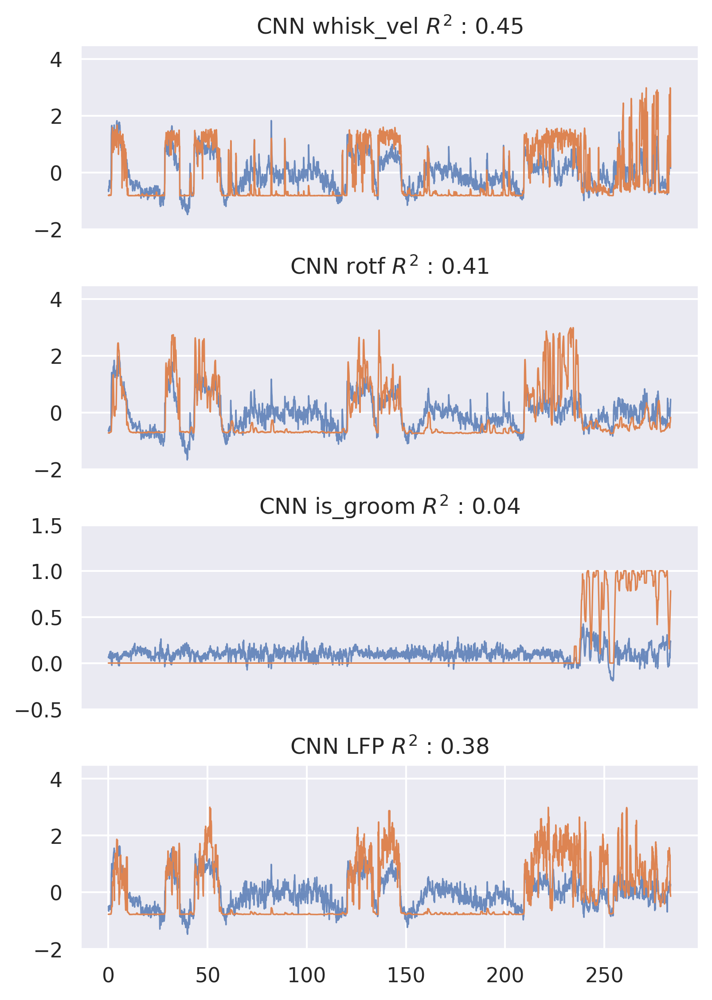

In [106]:
plt.figure(figsize=(6,9),dpi=300)
for i, name in enumerate(['whisk_vel', 'rotf', 'is_groom', 'LFP']):
    plt.subplot(4,1,i+1)
    t_range = np.r_[range(1280,2000),range(3000,5000),range(7000,8000),range(9000,10950)]
    t_ax = np.divide(range(len(t_range)),20)
    plt.plot(t_ax,y_predict[t_range,i],label='prediction',linewidth=0.8,alpha=0.8)
    plt.plot(t_ax,y[t_range,i],label='real test data',linewidth=0.8,alpha=1)


    r22 = r2_score(y[:,i],y_predict[:,i])
    if i+1<4:
        plt.xticks([])
    if name=='is_groom':
        plt.ylim([-0.5,1.5])
    else:
        plt.ylim([-2,4.5])
#     plt.legend()
    plt.title('CNN '+name+ ' $R^2$ : '+str(round(r22,2)))
plt.subplots_adjust(hspace=0.3)
# plt.savefig(save_path+'svgs/'+mouse+'_cnn_single_trial.svg', format='svg',dpi=300)
